<div align="center" style="text-align: center; padding: 50px 0; border-top: 4px solid #1f4e79; border-bottom: 4px solid #1f4e79;">

<h1 style="text-align: center; color: #1f4e79; margin-bottom: 8px;">Forecasting US Electricity and Gas Output</h1>

<h3 style="text-align: center; color: #555; font-weight: normal;">Time Series Analysis: ETS + ARIMA vs Facebook Prophet</h3>

<br>

<p style="text-align: center; font-size: 16px;"><b>Author:</b> Tanguy Mandrillon &nbsp;|&nbsp; <b>Year:</b> 2026</p>

</div>


> **Note on AI usage:** AI (Claude Code) was used as an assistant to write the code of this notebook, to draft the text and to design the layout (title page, table of contents and plot style). The analysis was led by me. Details and prompts are in section 4.

# Introduction

In this notebook, we analyze a time series and forecast it with two different methods.

In the first approach, we apply an ETS decomposition to split the series into its trend, seasonal and residual components. The trend and seasonality are extrapolated, while the residual $R_t$ is modeled with an ARIMA model. We then recombine the three components to obtain the final forecast and compare it with the test set.

The second approach uses Facebook Prophet, a more automated method, to produce the same forecast.

Finally, we compare both approaches using error metrics and draw conclusions.


## Table of contents

| Part | Content |
|---|---|
| **0. Dataset** | Import, plot and train-test split |
| **1. ETS Decomposition + ARIMA** | Model choice, trend, seasonality, residual forecasting, recomposition and errors |
| **2. Facebook Prophet** | Forecasting, errors and parameter tuning |
| **3. Conclusion** | Comparison of both approaches |
| **4. AI-usage policy** | Where AI was used, planning session and prompts |

---


In [1]:
import matplotlib.pyplot as plt

# Global plot style shared by all the figures of the notebook
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "#fafafa",
    "axes.grid": True,
    "grid.color": "#dddddd",
    "grid.linestyle": "-",
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#444444",
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlepad": 12,
    "axes.labelsize": 11,
    "axes.labelcolor": "#333333",
    "legend.frameon": True,
    "legend.framealpha": 0.9,
    "legend.edgecolor": "#cccccc",
    "legend.fontsize": 9,
    "lines.linewidth": 1.2,
    "font.size": 10,
})


# 0. Dataset
First of all, we need to find a suitable time series (TS). For the analysis to make sense, the TS should have three distinct components: trend, seasonality and residual.

Energy production is a natural candidate: it grows with the economy and the population (trend), and it follows the weather (seasonality), with heating in winter and air conditioning in summer.

We use the [IPG2211A2N](https://fred.stlouisfed.org/series/IPG2211A2N) series from FRED (Federal Reserve Bank of St. Louis): the industrial production index of US electric and gas utilities, monthly, with 2017 = 100, **not seasonally adjusted**. The source is the Industrial Production release (G.17) of the Federal Reserve Board. The seasonally adjusted version must not be used, otherwise the seasonal component we want to study would already be removed.

## 0.1. Import dataset
Let's start by loading the dataset into a pandas DataFrame.

The file `IPG2211A2N.csv` has two columns: `observation_date` (first day of the month) and `IPG2211A2N` (the index). It covers January 1939 to August 2026. We keep **January 1995 onwards** (380 months): 30 years are enough to estimate a stable seasonal profile, and the older decades (much faster growth, oil shocks) say little about today's energy sector. We rename the column to `output`, check that there is no missing value, and set an explicit monthly frequency (`MS`, month start) on the index, which statsmodels needs.

In [2]:
import pandas as pd

raw = pd.read_csv("IPG2211A2N.csv", parse_dates=["observation_date"], index_col="observation_date")

# Monthly output of US electric and gas utilities, index 2017 = 100 (not seasonally adjusted)
df = raw.rename(columns={"IPG2211A2N": "output"})
df.index.name = "date"
# Analysis window: January 1995 onwards
df = df.loc["1995-01-01":]
print(f"Missing values: {df['output'].isna().sum()}")
# Explicit monthly frequency (month start), needed by statsmodels
df = df.asfreq("MS")

df

Missing values: 0


,output
date,
1995-01-01,91.3554
1995-02-01,86.3571
1995-03-01,80.3024
1995-04-01,72.9393
1995-05-01,72.4021
...,...
2026-04-01,94.5652
2026-05-01,97.7156
2026-06-01,110.7733


## 0.2. Plot TS

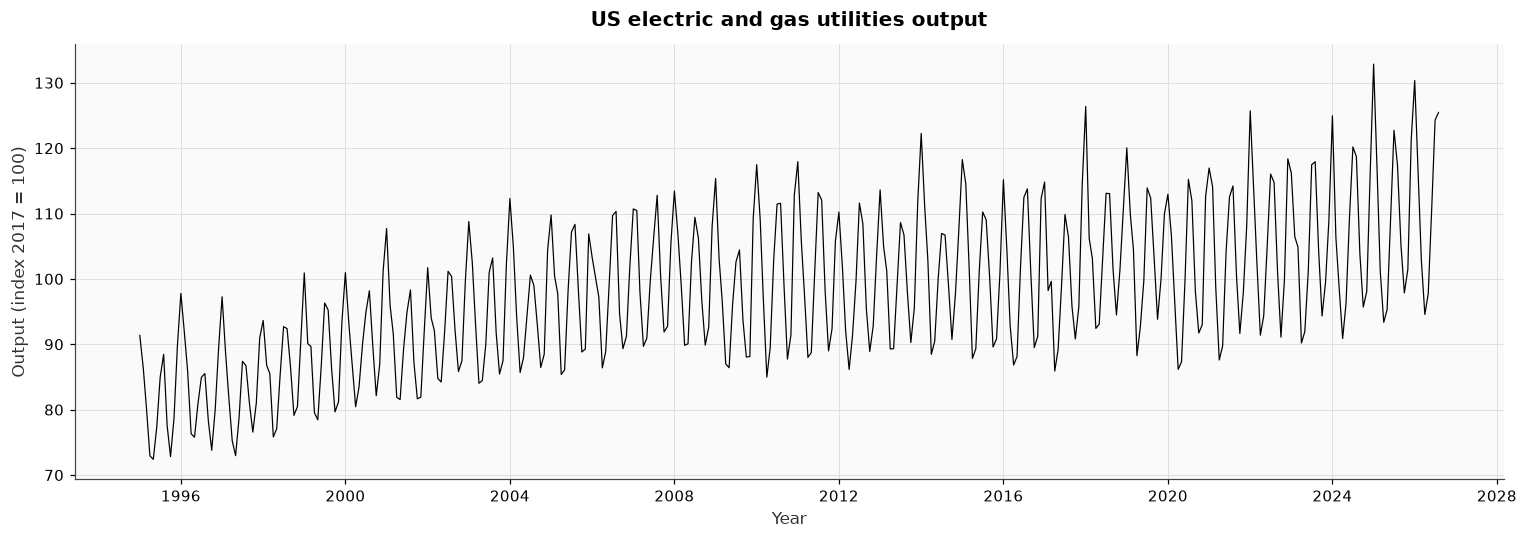

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df.output, color="black", linewidth=0.8)
ax.set_title("US electric and gas utilities output")
ax.set_xlabel("Year")
ax.set_ylabel("Output (index 2017 = 100)")
plt.tight_layout()
plt.show()

> Seasonality?

The series shows a very regular yearly pattern with **two peaks**: a high one in winter (January, heating) and a second one in July-August (air conditioning). The lows are in spring (April-May) and in autumn (October), when there is little need for heating or cooling. The seasonal swings get bigger as the series grows: about 25 points between the highest and the lowest month in the late 1990s, about 35 points in recent years.

> Trend?

The yearly average grows from about 81 in 1995 to about 107 in 2024, but not at a constant speed: fast growth until the mid-2000s, an almost flat level from about 2007 to 2016, then growth again. Unlike retail or transport series, there is no big shock: in 2020 the yearly average only dipped from 104.0 to 101.0. The month-to-month noise mostly comes from the weather (a cold winter or a hot summer).

## 0.3. train-test split
To compute the errors between our forecast and reality, we have to keep a part of the data to test our result. We keep the year 2025 plus the first eight months of 2026 as test set. The train set contains only complete years, which is convenient for the yearly windows used later.

Train-set: January 1995 -> December 2024 (360 months, 30 years)

Test-set: January 2025 -> August 2026 (20 months)

In [4]:
df_train = df.loc[:"2024-12-01"]
df_test = df.loc["2025-01-01":]

print(f"Train: {df_train.index.min():%Y-%m} -> {df_train.index.max():%Y-%m} ({len(df_train)} months)")
print(f"Test:  {df_test.index.min():%Y-%m} -> {df_test.index.max():%Y-%m} ({len(df_test)} months)")

Train: 1995-01 -> 2024-12 (360 months)
Test:  2025-01 -> 2026-08 (20 months)


# 1. ETS Decomposition + ARIMA
We will perform the ETS Decomposition. Our decomposition/recomposition will follow the next steps:
1. Determine the model (additive or multiplicative)
1. Determine if there is a trend component (Anova test)
1. Estimate the trend using CMA (Center Moving Average)
1. Detrend
1. Determine if there is a seasonal component (Anova test)
1. Forecast St and ensure area conservation is met
1. Remove seasonality, $Y_t' = R_t \cdot T_t$
1. Compute and forecast the trend (method varies depending on linearity)
1. Remove trend, $Y_t'' = R_t$
1. Forecast R_t using ARIMA model
1. Recomposition
1. Error's measurement


## 1.1. Additive or Multiplicative

In [5]:
import statsmodels.api as sm

# One window per calendar year = one full seasonal cycle (12 months), on the train set only
windows = df_train["output"].groupby(df_train.index.year).agg(mean="mean", std="std", n="size")
windows = windows[windows["n"] == 12]

# Fit Std = a * mean + b + e
X = sm.add_constant(windows["mean"])
ols = sm.OLS(windows["std"], X).fit()
print(ols.summary().tables[1])

# t-test on H0: a = 0 at the 5% level
alpha = 0.05
a_hat = ols.params["mean"]
t_stat = ols.tvalues["mean"]
p_value = ols.pvalues["mean"]
print(f"\na = {a_hat:.4f}, t = {t_stat:.3f}, p-value = {p_value:.2e}")
if p_value < alpha:
    print("H0 rejected: the std grows with the level -> multiplicative model")
else:
    print("H0 not rejected: the std does not depend on the level -> additive model")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -7.8641      2.066     -3.806      0.001     -12.096      -3.632
mean           0.1730      0.021      8.158      0.000       0.130       0.216

a = 0.1730, t = 8.158, p-value = 7.01e-09
H0 rejected: the std grows with the level -> multiplicative model


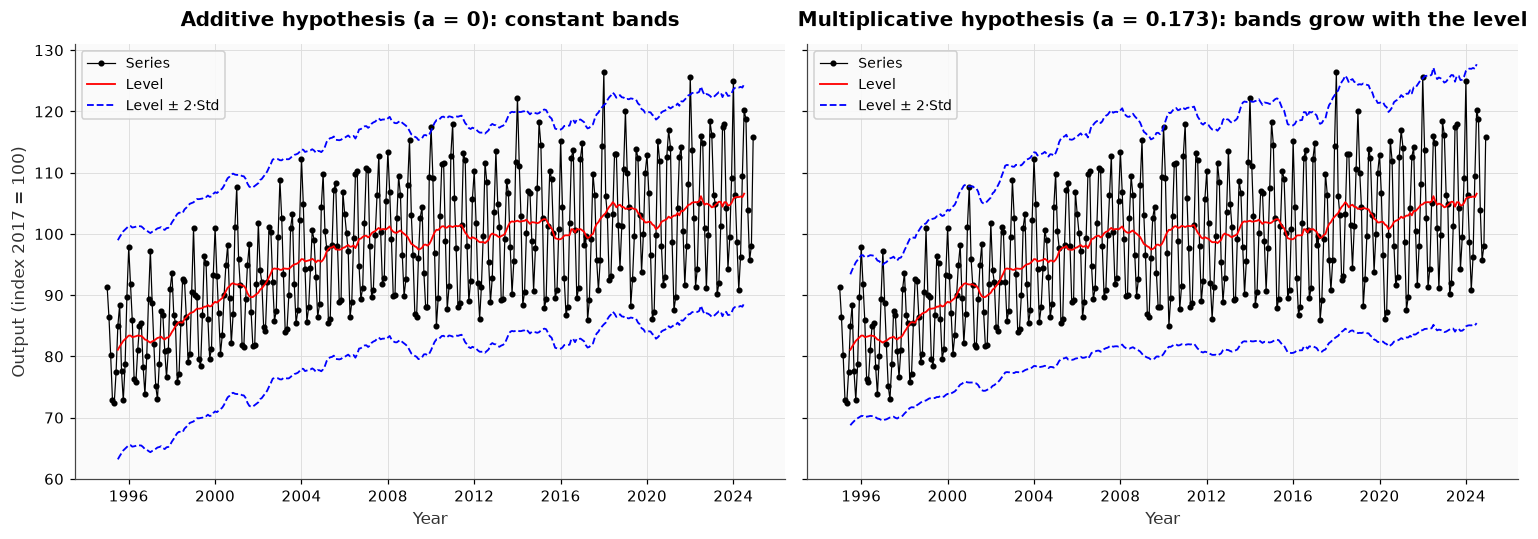

In [6]:
k = 2  # band half-width, in number of standard deviations

# Level: 12-month centered moving average
level = df_train["output"].rolling(12, center=True).mean()

# Additive hypothesis (a = 0): constant spread, equal to the average yearly std
std_add = windows["std"].mean()
# Multiplicative hypothesis: spread proportional to the level, from the fit Std = a * mean + b
std_mult = ols.params["mean"] * level + ols.params["const"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
bands = [
    (axes[0], std_add, "Additive hypothesis (a = 0): constant bands"),
    (axes[1], std_mult, f"Multiplicative hypothesis (a = {a_hat:.3f}): bands grow with the level"),
]
for ax, spread, title in bands:
    ax.plot(df_train.index, df_train["output"], color="black", marker=".", linewidth=0.8, label="Series")
    ax.plot(level.index, level, color="red", label="Level")
    ax.plot(level.index, level + k * spread, color="blue", linestyle="--", label=f"Level ± {k}·Std")
    ax.plot(level.index, level - k * spread, color="blue", linestyle="--")
    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.legend(loc="upper left")
axes[0].set_ylabel("Output (index 2017 = 100)")
plt.tight_layout()
plt.show()

> Additive or multiplicative ?

The t-test rejects $a = 0$ ($a = 0.173$, $t = 8.16$, p-value $= 7 \times 10^{-9}$). The yearly standard deviation grows with the yearly mean: when the output is higher, the gap between the winter peak and the spring low grows with it. Graphically, the bands of the multiplicative hypothesis (right) are narrow in the 1990s and wide in the 2020s, like the series, while the constant bands (left) are clearly too wide in the 1990s.

TS's model: $Y_t = T_t \cdot S_t \cdot R_t$

In practical terms, the seasonal effect is a **percentage** of the activity ("January is 15% above an average month"), not a fixed number of index points.

## 1.2. Trend Component

### 1.2.1. Is there a trend ?
We'll perform an Anova test on the Buys-Ballot table (output by year and by month) to determine if there is a trend or not.

month,1,2,3,4,5,6,7,8,9,10,11,12,Average
year,,,,,,,,,,,,,
1995,91.4,86.4,80.3,72.9,72.4,77.4,85.0,88.5,77.6,72.8,78.7,89.7,81.1
1996,97.8,91.8,85.9,76.3,75.8,81.0,84.9,85.5,78.3,73.8,80.1,89.4,83.4
1997,97.3,88.7,82.0,75.2,73.0,78.8,87.4,86.7,81.0,76.6,81.1,91.0,83.2
1998,93.6,86.8,85.5,75.8,77.1,85.4,92.7,92.4,86.5,79.1,80.5,90.6,85.5
1999,100.9,90.1,89.7,79.5,78.4,86.8,96.3,95.3,86.2,79.7,81.2,93.4,88.1
2000,101.0,93.1,87.0,80.4,83.5,90.0,94.9,98.2,89.6,82.1,86.9,101.2,90.7
2001,107.7,95.9,91.7,81.9,81.5,89.3,94.9,98.3,87.2,81.7,81.9,91.9,90.3
2002,101.7,94.0,92.1,84.8,84.2,92.1,101.2,100.4,92.2,85.8,87.5,99.5,93.0
2003,108.8,102.5,93.4,84.0,84.5,90.0,101.0,103.2,91.8,85.5,87.5,102.3,94.5


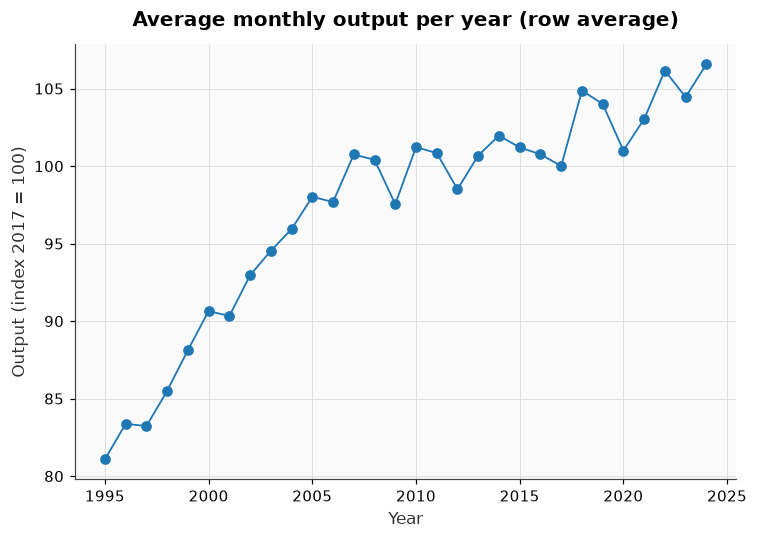

In [7]:
# Buys-Ballot table on the train set: years as rows, months as columns
long = pd.DataFrame(
    {"output": df_train["output"], "year": df_train.index.year, "month": df_train.index.month}
)
table = long.pivot(index="year", columns="month", values="output")

year_mean = table.mean(axis=1)  # average by row
month_mean = table.mean(axis=0)  # average by column

# Display the table with the averages as margins
display_table = table.copy()
display_table["Average"] = year_mean
display_table.loc["Average"] = pd.concat([month_mean, pd.Series({"Average": table.stack().mean()})])
display(display_table.round(1))

fig, axes = plt.subplots(1, 1, figsize=(7, 5))
axes.plot(year_mean.index, year_mean, marker="o")
axes.set_title("Average monthly output per year (row average)")
axes.set_xlabel("Year")
axes.set_ylabel("Output (index 2017 = 100)")
plt.tight_layout()
plt.show()

In [8]:
import statsmodels.formula.api as smf

# Two-way Anova on the Buys-Ballot table (year + month factors, no interaction).
# The month factor absorbs the seasonality, so the year factor tests
# H0: all yearly means are equal (no trend) against H1: at least one differs.
anova_fit = smf.ols("output ~ C(year) + C(month)", data=long).fit()
anova = sm.stats.anova_lm(anova_fit)
print(anova)

f_year = anova.loc["C(year)", "F"]
p_year = anova.loc["C(year)", "PR(>F)"]
print(f"\nYear factor: F = {f_year:.2f}, p-value = {p_year:.2e}")
if p_year < alpha:
    print("H0 rejected: the yearly means differ -> there is a trend")
else:
    print("H0 not rejected: the yearly means are equal -> no trend")

             df        sum_sq      mean_sq           F         PR(>F)
C(year)    29.0  17799.149815   613.763787   74.553489  5.515322e-124
C(month)   11.0  24477.794802  2225.254073  270.300167  2.200240e-154
Residual  319.0   2626.176876     8.232529         NaN            NaN

Year factor: F = 74.55, p-value = 5.52e-124
H0 rejected: the yearly means differ -> there is a trend


> Is there a trend ?

The row averages grow from about 81 in 1995 to about 107 in 2024, and the plot shows the flat period between about 2007 and 2016. The column averages show the seasonal profile: January (111.3) and July-August (105.6) are the highest months, April (85.3) and May (86.7) the lowest.

The two-way Anova rejects H0 for the year factor ($F = 74.6$, p-value far below 5%): the yearly means are not all equal, so **there is a trend component** in the series. Note that the month factor is even more significant ($F = 270$), which announces the seasonality.

### 1.2.2. Estimate the trend
To do so, we'll compute a CMA(12) to obtain a smooth trend. We choose 12 because it is the number of components in a year (12 months).


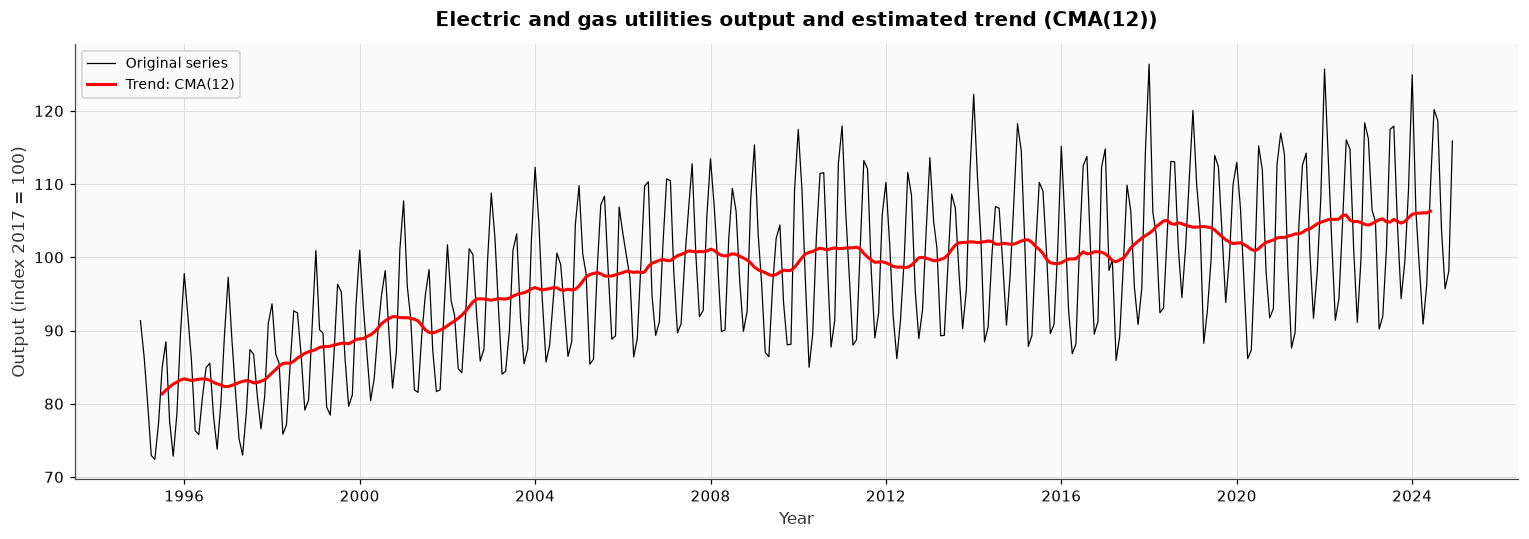

In [9]:
# CMA(12): the order is even, so a plain 12-month window is not centered on a month.
# We use a 2x12 moving average, i.e. weights [1/24, 1/12, ..., 1/12, 1/24] over 13 months,
# which is centered on month t and covers exactly one year.
# The first and last 6 months have no CMA value.
cma = df_train["output"].rolling(12).mean().rolling(2).mean().shift(-6)
df_train = df_train.assign(cma=cma)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_train.index, df_train["output"], color="black", linewidth=0.8, label="Original series")
ax.plot(df_train.index, df_train["cma"], color="red", linewidth=2, label="Trend: CMA(12)")
ax.set_title("Electric and gas utilities output and estimated trend (CMA(12))")
ax.set_xlabel("Year")
ax.set_ylabel("Output (index 2017 = 100)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

> Trend

The red line is our estimated trend. It has been obtained with a CMA(12) on the original Time Series. Doing that, we lose the 6 first points and the 6 last points. This is not a problem because we still have 348 points to compute our average by season.

The CMA shows three phases: a steady growth until about 2007, a plateau until about 2016, and a slower growth afterwards. It also moves a little with unusual winters or summers, because a 12-month average is pulled up or down for a whole year by one extreme month. A straight line will therefore not be enough to describe this trend (see section 1.4).

### 1.2.3. Detrend
We will remove the trend to our original Time Series to be able to decompose the seasonal component. If the model is multiplicative we divide the original TS by the estimated trend, otherwise we subtract it (see section 1.1 for the choice of the model).


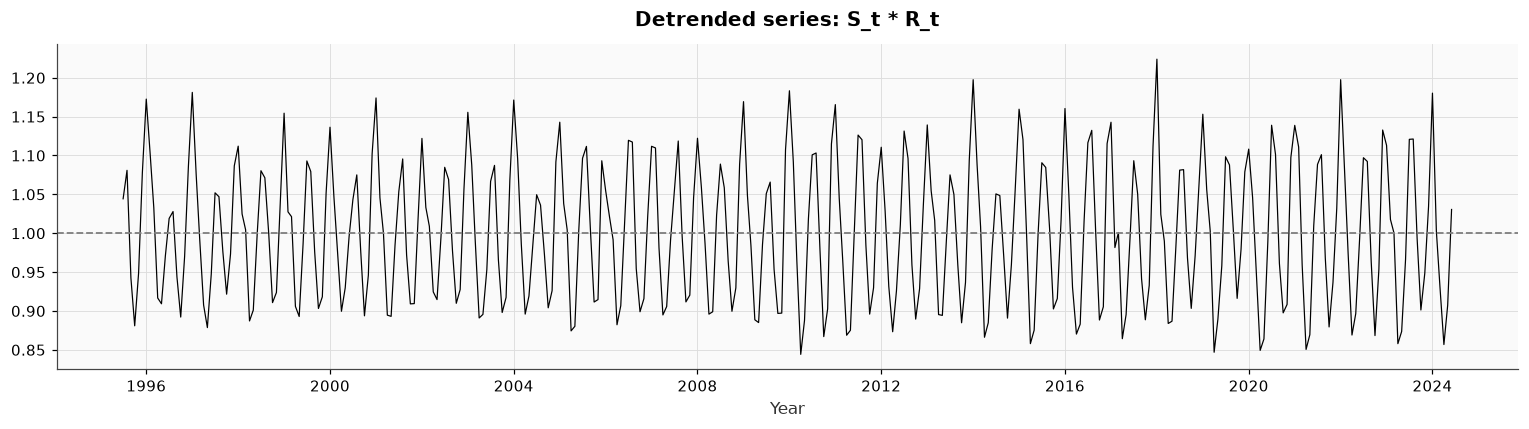

In [10]:
# Multiplicative model: Y_t / T_t = S_t * R_t
# The CMA is NaN for the first and last 6 months, so the ratio is NaN there too
df_train = df_train.assign(seasonal_residual=df_train["output"] / df_train["cma"])

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df_train.index, df_train.seasonal_residual, color="black", linewidth=0.8)
ax.axhline(1, color="grey", linestyle="--")
ax.set_title("Detrended series: S_t * R_t")
ax.set_xlabel("Year")
plt.tight_layout()
plt.show()

## 1.3. Seasonal Component

### 1.3.1. Is there a seasonal component ?
We'll perform an Anova test on the average of the detrended series per month to determine if there is a seasonal component or not.


month,1,2,3,4,5,6,7,8,9,10,11,12,Average
year,,,,,,,,,,,,,
1995,NaN,NaN,NaN,NaN,NaN,NaN,1.044,1.081,0.942,0.881,0.949,1.078,0.996
1996,1.173,1.102,1.033,0.917,0.909,0.971,1.019,1.028,0.944,0.892,0.970,1.086,1.004
1997,1.181,1.075,0.992,0.908,0.879,0.948,1.052,1.047,0.976,0.922,0.973,1.087,1.003
1998,1.112,1.025,1.004,0.887,0.901,0.999,1.080,1.071,0.999,0.911,0.924,1.039,0.996
1999,1.154,1.028,1.021,0.906,0.893,0.986,1.093,1.079,0.976,0.903,0.918,1.052,1.001
2000,1.136,1.047,0.976,0.900,0.930,0.996,1.043,1.075,0.978,0.894,0.946,1.102,1.002
2001,1.174,1.046,1.000,0.895,0.893,0.985,1.053,1.096,0.972,0.909,0.909,1.018,0.996
2002,1.122,1.033,1.009,0.925,0.915,0.994,1.085,1.069,0.977,0.910,0.928,1.056,1.002
2003,1.156,1.088,0.990,0.891,0.896,0.953,1.067,1.087,0.966,0.898,0.917,1.069,0.998


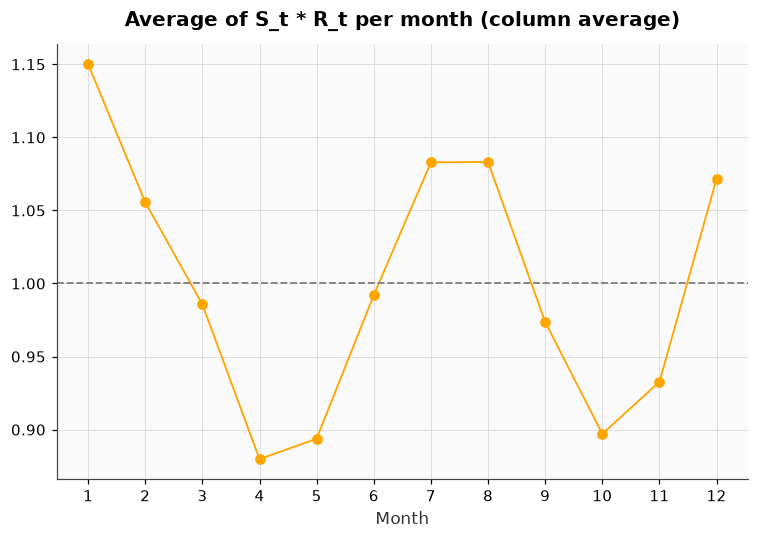

In [11]:
# Buys-Ballot table of the detrended series (S_t * R_t): years as rows, months as columns
# The first 6 and last 6 months are NaN (no CMA value), so they are dropped
detrended = df_train["seasonal_residual"].dropna()
long_s = pd.DataFrame(
    {"seasonal_residual": detrended, "year": detrended.index.year, "month": detrended.index.month}
)
table_s = long_s.pivot(index="year", columns="month", values="seasonal_residual")

year_mean_s = table_s.mean(axis=1)  # average by row
month_mean_s = table_s.mean(axis=0)  # average by column

# Display the table with the averages as margins
display_table_s = table_s.copy()
display_table_s["Average"] = year_mean_s
display_table_s.loc["Average"] = pd.concat([month_mean_s, pd.Series({"Average": table_s.stack().mean()})])
display(display_table_s.round(3))

fig, axes = plt.subplots(1, 1, figsize=(7, 5))
axes.plot(month_mean_s.index, month_mean_s, marker="o", color="orange")
axes.axhline(1, color="grey", linestyle="--")
axes.set_title("Average of S_t * R_t per month (column average)")
axes.set_xlabel("Month")
axes.set_xticks(range(1, 13))
plt.tight_layout()
plt.show()

In [12]:
# One-way Anova with the month as factor, on the detrended series.
# H0: all monthly means are equal (no seasonality) against H1: at least one differs.
anova_s_fit = smf.ols("seasonal_residual ~ C(month)", data=long_s).fit()
anova_s = sm.stats.anova_lm(anova_s_fit)
print(anova_s)

f_month = anova_s.loc["C(month)", "F"]
p_month = anova_s.loc["C(month)", "PR(>F)"]
print(f"\nMonth factor: F = {f_month:.2f}, p-value = {p_month:.2e}")
if p_month < alpha:
    print("H0 rejected: the monthly means differ -> there is a seasonal component")
else:
    print("H0 not rejected: the monthly means are equal -> no seasonal component")

             df    sum_sq   mean_sq           F         PR(>F)
C(month)   11.0  2.504680  0.227698  338.574942  2.216885e-174
Residual  336.0  0.225966  0.000673         NaN            NaN

Month factor: F = 338.57, p-value = 2.22e-174
H0 rejected: the monthly means differ -> there is a seasonal component


> Is there a seasonal component ?

The column averages show a clear seasonal profile with two peaks. January is far above the trend (1.150), followed by July and August (1.083 each), December (1.072) and February (1.056). The lowest months are April (0.880), May (0.894) and October (0.897).

The Anova test rejects H0 ($F = 339$, p-value far below 5%): the monthly means are not all equal, so **there is a seasonal component** in the series.

The average of the averages is 0.99986, very close to 1 but not exactly. We therefore implement the area conservation explicitly in the next section.

### 1.3.2. Forecast and area conservation
We almost forecast our seasonal component, but we need to ensure the area conservation is met: the 12 seasonal coefficients must average exactly 1 (multiplicative model).


In [13]:
# Area conservation: divide each monthly average by the average of averages,
# so that the 12 seasonal coefficients average exactly 1 (sum = 12)
average_of_average = month_mean_s.mean()
seasonal_coef = month_mean_s / average_of_average

# New row in the matrix with the seasonal coefficients
display_table_s.loc["Seasonal coefficient"] = pd.concat(
    [seasonal_coef, pd.Series({"Average": seasonal_coef.mean()})]
)
display(display_table_s.round(3))

print(f"Average of averages before correction: {average_of_average:.6f}")
print(f"Sum of the seasonal coefficients: {seasonal_coef.sum():.6f}")

# Seasonal component S_t: each month gets the coefficient of its calendar month.
# Unlike the CMA, it is defined for every month, including the first and last 6.
df_train = df_train.assign(seasonal=df_train.index.month.map(seasonal_coef).to_numpy())

df_train

month,1,2,3,4,5,6,7,8,9,10,11,12,Average
year,,,,,,,,,,,,,
1995,NaN,NaN,NaN,NaN,NaN,NaN,1.044,1.081,0.942,0.881,0.949,1.078,0.996
1996,1.173,1.102,1.033,0.917,0.909,0.971,1.019,1.028,0.944,0.892,0.970,1.086,1.004
1997,1.181,1.075,0.992,0.908,0.879,0.948,1.052,1.047,0.976,0.922,0.973,1.087,1.003
1998,1.112,1.025,1.004,0.887,0.901,0.999,1.080,1.071,0.999,0.911,0.924,1.039,0.996
1999,1.154,1.028,1.021,0.906,0.893,0.986,1.093,1.079,0.976,0.903,0.918,1.052,1.001
2000,1.136,1.047,0.976,0.900,0.930,0.996,1.043,1.075,0.978,0.894,0.946,1.102,1.002
2001,1.174,1.046,1.000,0.895,0.893,0.985,1.053,1.096,0.972,0.909,0.909,1.018,0.996
2002,1.122,1.033,1.009,0.925,0.915,0.994,1.085,1.069,0.977,0.910,0.928,1.056,1.002
2003,1.156,1.088,0.990,0.891,0.896,0.953,1.067,1.087,0.966,0.898,0.917,1.069,0.998


Average of averages before correction: 0.999860
Sum of the seasonal coefficients: 12.000000


,output,cma,seasonal_residual,seasonal
date,,,,
1995-01-01,91.3554,NaN,NaN,1.150264
1995-02-01,86.3571,NaN,NaN,1.055780
1995-03-01,80.3024,NaN,NaN,0.985816
1995-04-01,72.9393,NaN,NaN,0.879923
1995-05-01,72.4021,NaN,NaN,0.893925
...,...,...,...,...
2024-08-01,118.7029,NaN,NaN,1.083330
2024-09-01,103.8493,NaN,NaN,0.973766
2024-10-01,95.6967,NaN,NaN,0.897230


> Seasonal component

Each calendar month now has its coefficient $S_m$, and the 12 coefficients sum to exactly 12. The seasonal component has no NaN, because it repeats itself every year.

Practical reading: in January the output is on average **15% above** a typical month (heating), in July and August 8% above (air conditioning), and in April, May and October 10 to 12% below. The rows of the table are stable over 30 years, so fixed coefficients are a reasonable choice. The differences between years come from the weather: January goes from 1.054 in 2006 (a mild winter) to 1.224 in 2018 (a cold one). These weather effects cannot be predicted from the calendar, so they will end up in the residual $R_t$.

### 1.3.3. Remove Seasonality
We are now able to compute a TS with the trend and the residual component. Based on this we'll forecast the trend.


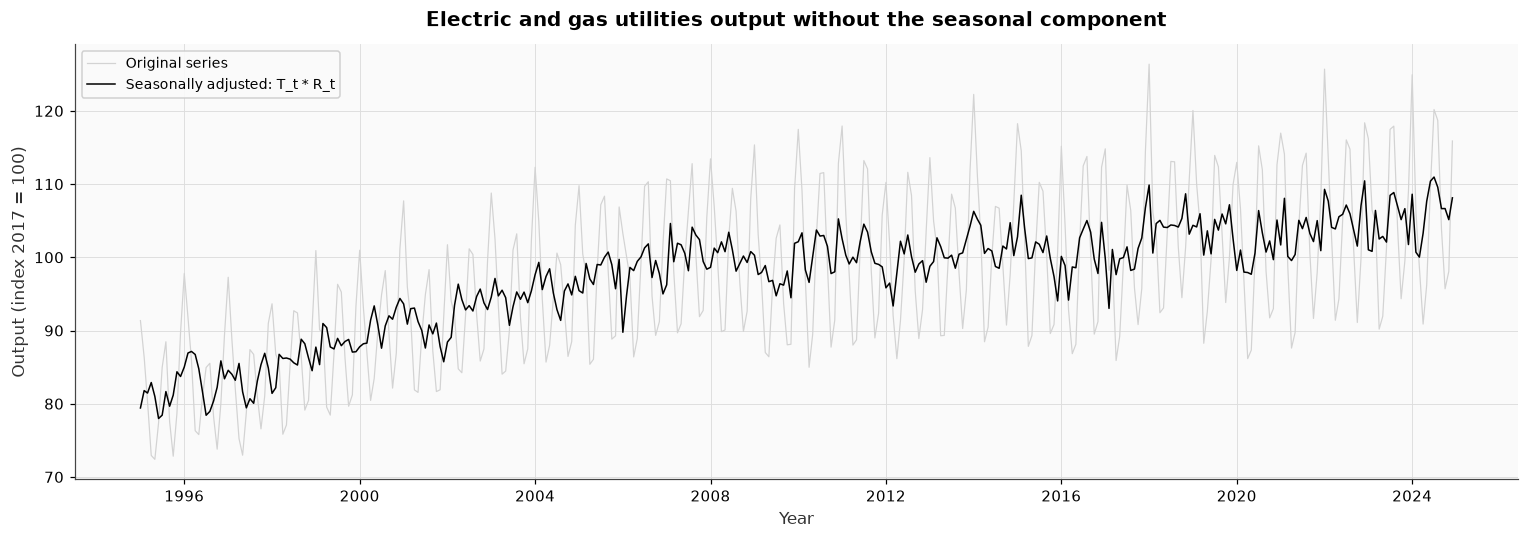

,output,cma,seasonal_residual,seasonal,trend_residual
date,,,,,
1995-01-01,91.3554,NaN,NaN,1.150264,79.421213
1995-02-01,86.3571,NaN,NaN,1.055780,81.794607
1995-03-01,80.3024,NaN,NaN,0.985816,81.457807
1995-04-01,72.9393,NaN,NaN,0.879923,82.892829
1995-05-01,72.4021,NaN,NaN,0.893925,80.993445
...,...,...,...,...,...
2024-08-01,118.7029,NaN,NaN,1.083330,109.572287
2024-09-01,103.8493,NaN,NaN,0.973766,106.647101
2024-10-01,95.6967,NaN,NaN,0.897230,106.657878


In [14]:
# Multiplicative model: Y_t / S_t = T_t * R_t
# The seasonal component is defined for every month, so there is no NaN here
df_train = df_train.assign(trend_residual=df_train["output"] / df_train["seasonal"])

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_train.index, df_train["output"], color="lightgrey", linewidth=0.8, label="Original series")
ax.plot(df_train.index, df_train["trend_residual"], color="black", linewidth=1, label="Seasonally adjusted: T_t * R_t")
ax.set_title("Electric and gas utilities output without the seasonal component")
ax.set_xlabel("Year")
ax.set_ylabel("Output (index 2017 = 100)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

df_train

## 1.4. Trend forecasting

### 1.4.1. Linear trends
We first fit a straight line by OLS on the seasonally adjusted series. The CMA of section 1.2.2 showed three phases, so we also fit a **piecewise linear trend**. It is still a linear regression, but its slope can change at two dates $\tau_1 < \tau_2$, without any jump:

$$T_t = b + a \, t + c_1 \, (t - \tau_1)^+ + c_2 \, (t - \tau_2)^+ \qquad \text{with } (x)^+ = \max(x, 0)$$

The slope is $a$ before $\tau_1$, $a + c_1$ between $\tau_1$ and $\tau_2$, and $a + c_1 + c_2$ after $\tau_2$. The breakpoints are not chosen by eye: we try every pair (each segment must be at least 36 months long) and keep the one with the smallest sum of squared errors. To forecast, we extend the last segment.

We also run a quick ADF test on the residual $R_t = Y'_t / T_t$ of each trend (the full stationarity tests are in section 1.5.1), because ARIMA needs a stationary residual.

Straight line: T_t = 0.0616 * t + 86.06   (R² = 0.750)



Piecewise linear trend (R² = 0.867), breakpoints: 2006-09, 2016-04
  segment starting 1995-01: slope = +1.642 points per year
  segment starting 2006-09: slope = +0.140 points per year
  segment starting 2016-04: slope = +0.611 points per year
Straight line: ADF p-value of the residual = 0.1209
Piecewise linear trend: ADF p-value of the residual = 0.0000


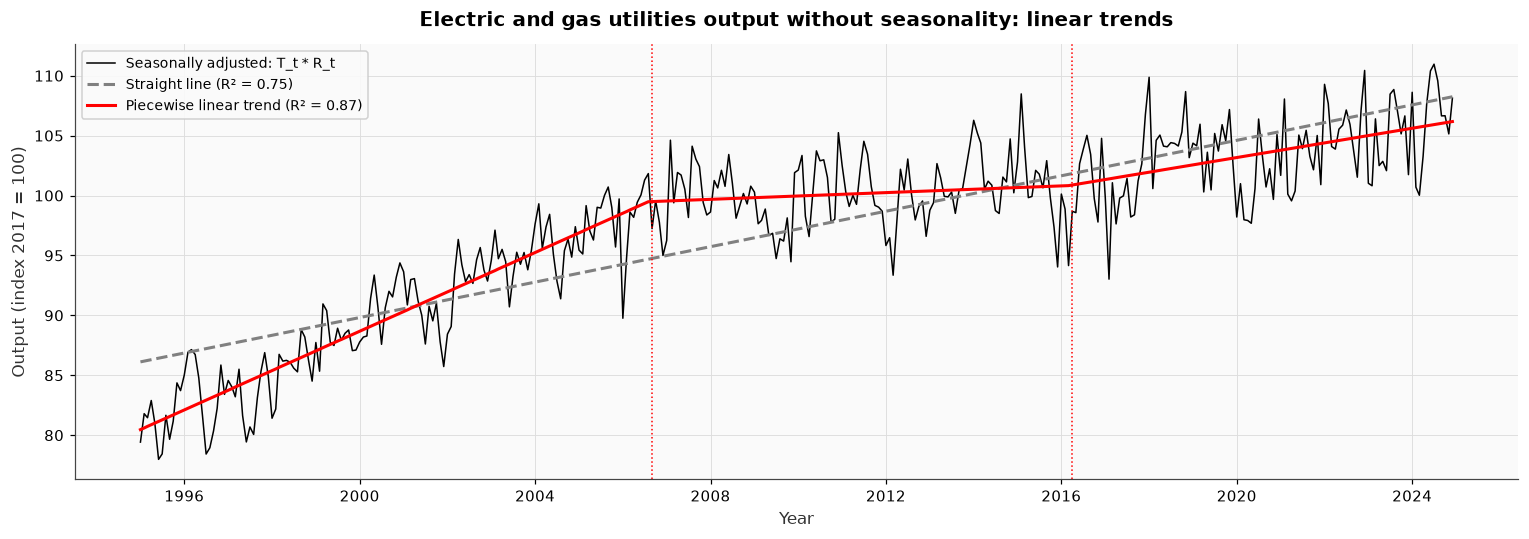

In [15]:
import warnings

import numpy as np
from statsmodels.tsa.stattools import adfuller


def hinge_design(t, breaks):
    """Design matrix of a continuous piecewise linear trend: columns 1, t, (t - tau_1)+, (t - tau_2)+, ..."""
    return np.column_stack([np.ones(len(t))] + [t] + [np.maximum(t - tau, 0) for tau in breaks])


# Time index t = 1, 2, ..., n, one step per month
n = len(df_train)
t = np.arange(1, n + 1)
y_adj = df_train["trend_residual"].to_numpy()  # seasonally adjusted series T_t * R_t

# 1) Straight line T_t = a * t + b, fitted by OLS
linear_trend = sm.OLS(y_adj, hinge_design(t, [])).fit()
print(f"Straight line: T_t = {linear_trend.params[1]:.4f} * t + {linear_trend.params[0]:.2f}   (R² = {linear_trend.rsquared:.3f})")


# 2) Piecewise linear trend with two breakpoints tau_1 < tau_2:
#    T_t = b + a * t + c_1 * (t - tau_1)+ + c_2 * (t - tau_2)+
#    The breakpoints are chosen by grid search: the pair with the smallest SSE wins.
def sse(breaks):
    _, ssr, *_ = np.linalg.lstsq(hinge_design(t, breaks), y_adj, rcond=None)
    return ssr[0]


min_segment = 36  # each segment covers at least 3 years, so a slope is never fitted on a few months
grid = [(tau1, tau2) for tau1 in range(min_segment, n - 2 * min_segment + 1)
        for tau2 in range(tau1 + min_segment, n - min_segment + 1)]
breaks = list(min(grid, key=sse))
pw_trend = sm.OLS(y_adj, hinge_design(t, breaks)).fit()

# Slope of each segment, in index points per year
segment_slopes = 12 * np.cumsum(pw_trend.params[1:])
segment_starts = [df_train.index[0]] + [df_train.index[tau] for tau in breaks]  # the new slope applies from t = tau + 1
print(f"\nPiecewise linear trend (R² = {pw_trend.rsquared:.3f}), breakpoints: "
      + ", ".join(f"{d:%Y-%m}" for d in segment_starts[1:]))
for start, slope in zip(segment_starts, segment_slopes):
    print(f"  segment starting {start:%Y-%m}: slope = {slope:+.3f} points per year")

# Quick check of the residual R_t = Y'_t / T_t of each trend: ADF test (H0: unit root), full tests in section 1.5.1
warnings.filterwarnings("ignore", category=FutureWarning)  # adfuller return-type notice
for name, fit in [("Straight line", linear_trend), ("Piecewise linear trend", pw_trend)]:
    adf_p = adfuller(y_adj / fit.fittedvalues, regression="c", autolag="AIC")[1]
    print(f"{name}: ADF p-value of the residual = {adf_p:.4f}")

# Trend component T_t: the piecewise linear trend
df_train = df_train.assign(trend_pw=pw_trend.predict(hinge_design(t, breaks)))

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_train.index, df_train["trend_residual"], color="black", linewidth=1, label="Seasonally adjusted: T_t * R_t")
ax.plot(df_train.index, linear_trend.predict(hinge_design(t, [])), color="grey", linestyle="--", linewidth=2,
        label=f"Straight line (R² = {linear_trend.rsquared:.2f})")
ax.plot(df_train.index, df_train["trend_pw"], color="red", linewidth=2, label=f"Piecewise linear trend (R² = {pw_trend.rsquared:.2f})")
for d in segment_starts[1:]:
    ax.axvline(d, color="red", linestyle=":", linewidth=1)
ax.set_title("Electric and gas utilities output without seasonality: linear trends")
ax.set_xlabel("Year")
ax.set_ylabel("Output (index 2017 = 100)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()


> Linear trends

The straight line ($R^2 = 0.750$, +0.74 point per year) does not follow the shape of the trend: it is above the series in the late 1990s and below it from about 2003 to 2010. These long deviations stay in the residual, and the ADF test does not reject a unit root (p-value = 0.12). With this trend, $R_t$ would not be stationary and the ARIMA step would not work (we tried: the residual has to be differenced and the AR model becomes unstable).

The piecewise linear trend fits much better ($R^2 = 0.867$). The grid search places the breakpoints in **September 2006** and **April 2016**, which matches the three phases seen on the CMA:

| Segment | Slope (points per year) |
|---|---|
| January 1995 - August 2006 | +1.64 |
| September 2006 - March 2016 | +0.14 (almost flat) |
| April 2016 - December 2024 | +0.61 |

Its residual is stationary (ADF p-value < 0.0001). **We keep the piecewise linear trend** for the rest of the ETS approach and drop the straight line. One limit for the forecast: the last slope is estimated on 9 years only, and 2024 is a little above the line.

### 1.4.2. Exponential Smoothing trend
We apply a double exponential smoothing (Brown's method, one parameter $0 < \lambda < 1$) on the seasonally adjusted series $Y'_t = T_t \cdot R_t$. The series is smoothed once, then the smoothed series is smoothed a second time.

**First smoothing:**

$$\hat{Y}_t = \lambda \, Y'_{t-1} + (1 - \lambda)\, \hat{Y}_{t-1}$$

**Second smoothing:**

$$\hat{\hat{Y}}_t = \lambda \, \hat{Y}_t + (1 - \lambda)\, \hat{\hat{Y}}_{t-1}$$

**Level and slope:**

$$b_t = 2\,\hat{Y}_t - \hat{\hat{Y}}_t \qquad a_t = \left(\hat{Y}_t - \hat{\hat{Y}}_t\right) \cdot \frac{\lambda}{1 - \lambda}$$

**Initialization:** $\hat{Y}_1 = \hat{\hat{Y}}_1 = Y'_1$

**Trend estimate on the train set:** $\hat{T}_t = b_t$

**Forecast** ($n$ = last train month, $h = 1, 2, \dots$):

$$\hat{T}_{n+h} = b_n + h \cdot a_n$$

**Choice of $\lambda$:** the fit error $\sum_t (Y'_t - b_t)^2$ keeps decreasing as $\lambda$ gets close to 1. With $\lambda \to 1$, $b_t$ copies the series and absorbs the residual $R_t$. We therefore fix $\lambda = 0.1$ to keep a smooth trend.


lambda = 0.1: last level b_n = 107.01, last slope a_n = 0.101 per month


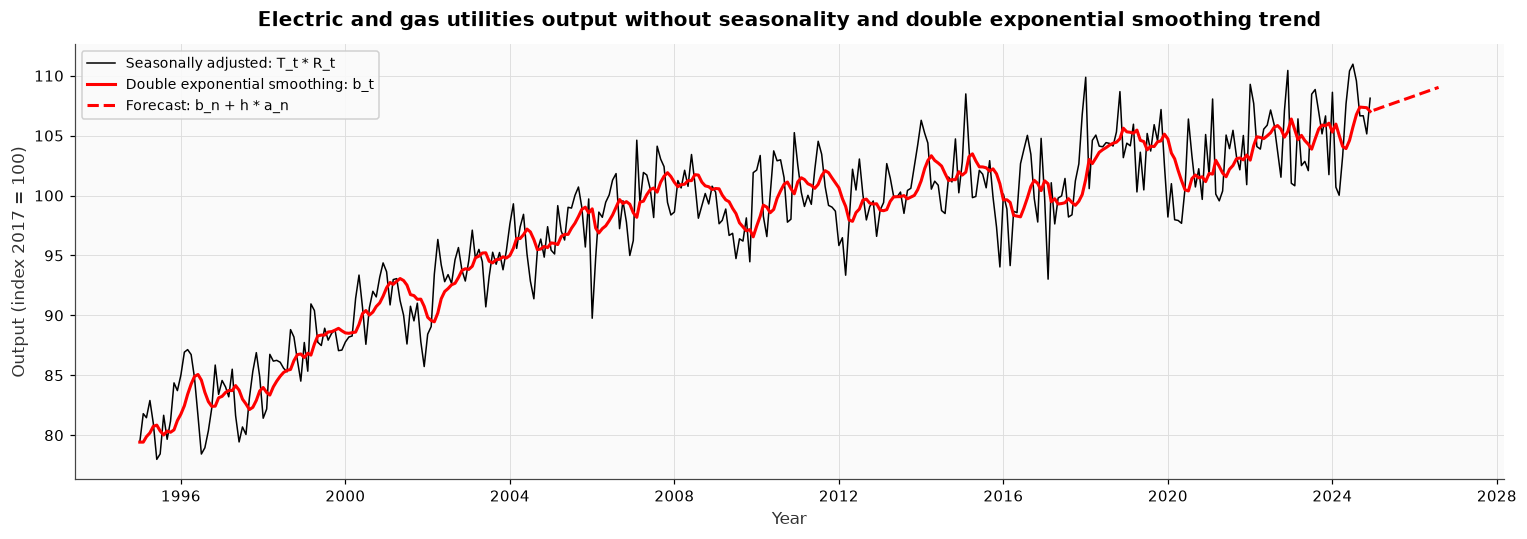

,output,cma,seasonal_residual,seasonal,trend_residual,trend_pw,trend_des
date,,,,,,,
1995-01-01,91.3554,NaN,NaN,1.150264,79.421213,80.462675,79.421213
1995-02-01,86.3571,NaN,NaN,1.055780,81.794607,80.599515,79.421213
1995-03-01,80.3024,NaN,NaN,0.985816,81.457807,80.736354,79.872158
1995-04-01,72.9393,NaN,NaN,0.879923,82.892829,80.873194,80.192656
1995-05-01,72.4021,NaN,NaN,0.893925,80.993445,81.010033,80.737564
...,...,...,...,...,...,...,...
2024-08-01,118.7029,NaN,NaN,1.083330,109.572287,105.969600,106.752868
2024-09-01,103.8493,NaN,NaN,0.973766,106.647101,106.020519,107.380553
2024-10-01,95.6967,NaN,NaN,0.897230,106.657878,106.071437,107.355110


In [16]:
def brown_double_smoothing(y, lam):
    """Brown's double exponential smoothing: returns the level b_t and the slope a_t."""
    s1 = np.empty(len(y))  # first smoothing: Y^_t
    s2 = np.empty(len(y))  # second smoothing: Y^^_t
    # Initialization: Y^_1 = Y^^_1 = Y'_1
    s1[0] = s2[0] = y[0]
    for t in range(1, len(y)):
        s1[t] = lam * y[t - 1] + (1 - lam) * s1[t - 1]
        s2[t] = lam * s1[t] + (1 - lam) * s2[t - 1]
    level = 2 * s1 - s2
    slope = (s1 - s2) * lam / (1 - lam)
    return level, slope


# The SSE keeps decreasing when lambda goes to 1 (b_t copies the series and absorbs R_t),
# so we fix a small lambda to keep a smooth trend
lambda_des = 0.1
level_des, slope_des = brown_double_smoothing(y_adj, lambda_des)

# Trend component T_t: the level b_t
df_train = df_train.assign(trend_des=level_des)

# Forecast over the test horizon: T_{n+h} = b_n + h * a_n
h = np.arange(1, len(df_test) + 1)
trend_des_forecast = pd.Series(level_des[-1] + h * slope_des[-1], index=df_test.index, name="trend_des")
print(f"lambda = {lambda_des}: last level b_n = {level_des[-1]:.2f}, last slope a_n = {slope_des[-1]:.3f} per month")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_train.index, df_train["trend_residual"], color="black", linewidth=1, label="Seasonally adjusted: T_t * R_t")
ax.plot(df_train.index, df_train["trend_des"], color="red", linewidth=2, label="Double exponential smoothing: b_t")
ax.plot(trend_des_forecast.index, trend_des_forecast, color="red", linestyle="--", linewidth=2, label="Forecast: b_n + h * a_n")
ax.set_title("Electric and gas utilities output without seasonality and double exponential smoothing trend")
ax.set_xlabel("Year")
ax.set_ylabel("Output (index 2017 = 100)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

df_train

> Exponential smoothing trend

This method uses the recent past to forecast the next values: the trend follows the plateau and the dips of the series, and it is extended with the last slope. At the end of the train set, the level is $b_n = 107.0$ and the slope is $a_n = 0.101$ point per month, i.e. **1.2 points per year**, twice the last slope of the piecewise linear trend (0.61). The DES trend reacts to the high level of 2024, so its forecast will be higher. It is difficult to know which method is best at this stage, so we will compare both after recomposition, with the error measurements.

### 1.4.3. Detrend
We now have to detrend with our piecewise linear trend or with our double exponential smoothing (DES) trend. After that, we'll fit an ARIMA model to forecast both residual components (piecewise linear and DES).

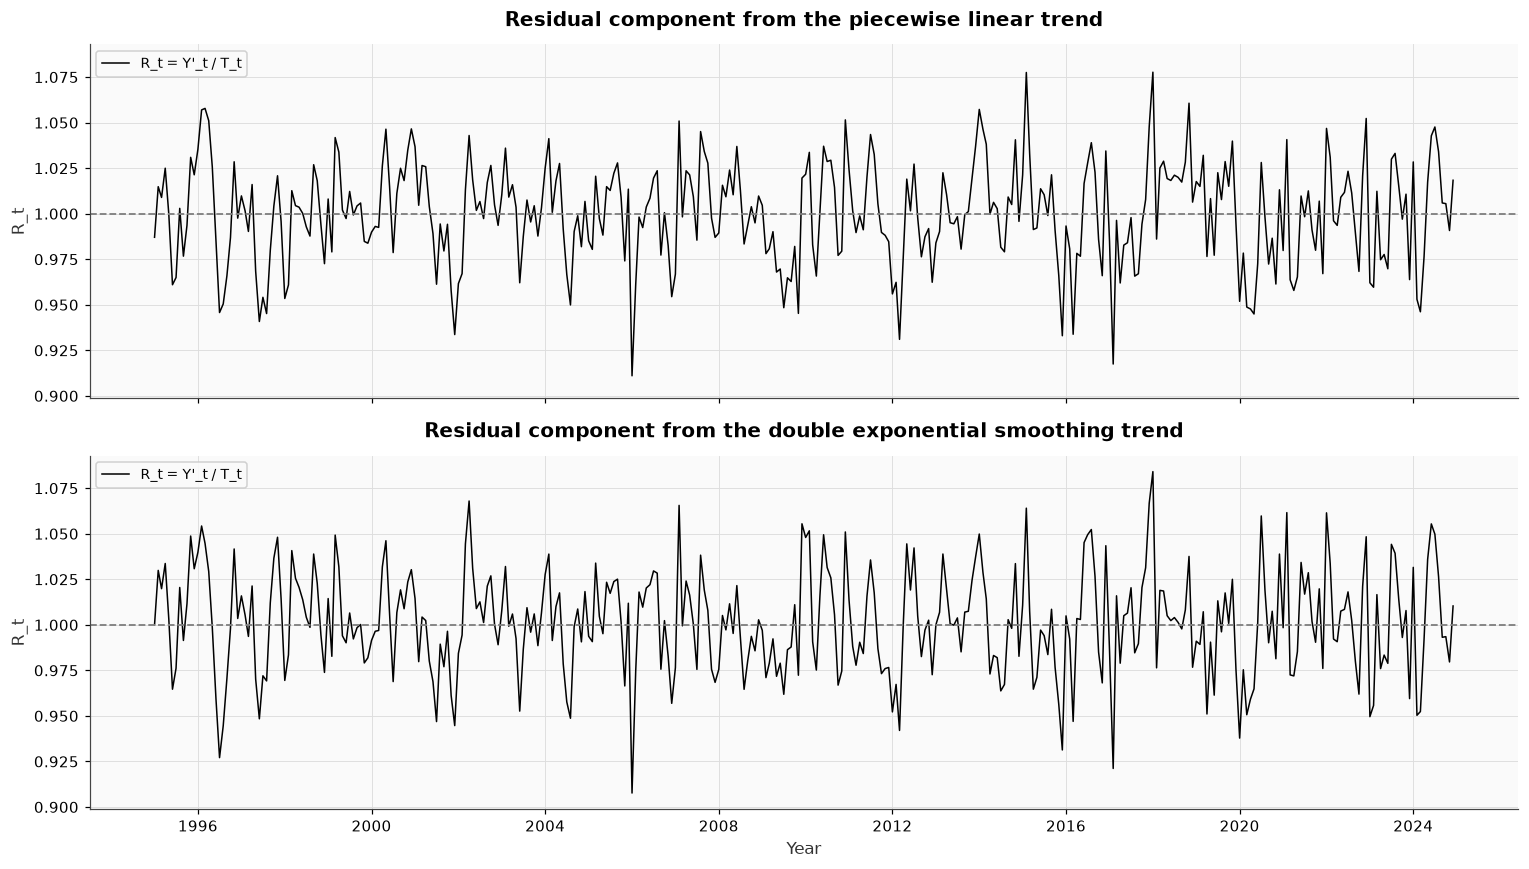

,output,cma,seasonal_residual,seasonal,trend_residual,trend_pw,trend_des,residual_pw,residual_des
date,,,,,,,,,
1995-01-01,91.3554,NaN,NaN,1.150264,79.421213,80.462675,79.421213,0.987057,1.000000
1995-02-01,86.3571,NaN,NaN,1.055780,81.794607,80.599515,79.421213,1.014828,1.029884
1995-03-01,80.3024,NaN,NaN,0.985816,81.457807,80.736354,79.872158,1.008936,1.019852
1995-04-01,72.9393,NaN,NaN,0.879923,82.892829,80.873194,80.192656,1.024973,1.033671
1995-05-01,72.4021,NaN,NaN,0.893925,80.993445,81.010033,80.737564,0.999795,1.003169
...,...,...,...,...,...,...,...,...,...
2024-08-01,118.7029,NaN,NaN,1.083330,109.572287,105.969600,106.752868,1.033997,1.026411
2024-09-01,103.8493,NaN,NaN,0.973766,106.647101,106.020519,107.380553,1.005910,0.993170
2024-10-01,95.6967,NaN,NaN,0.897230,106.657878,106.071437,107.355110,1.005529,0.993505


In [17]:
# Multiplicative model: Y'_t / T_t = (T_t * R_t) / T_t = R_t
# One residual component per trend estimate (piecewise linear and double exponential smoothing)
df_train = df_train.assign(
    residual_pw=df_train["trend_residual"] / df_train["trend_pw"],
    residual_des=df_train["trend_residual"] / df_train["trend_des"],
)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, sharey=True)
residuals = [
    (axes[0], "residual_pw", "Residual component from the piecewise linear trend"),
    (axes[1], "residual_des", "Residual component from the double exponential smoothing trend"),
]
for ax, col, title in residuals:
    ax.plot(df_train.index, df_train[col], color="black", linewidth=1, label="R_t = Y'_t / T_t")
    ax.axhline(1, color="grey", linestyle="--")
    ax.set_title(title)
    ax.set_ylabel("R_t")
    ax.legend(loc="upper left")
axes[1].set_xlabel("Year")
plt.tight_layout()
plt.show()

df_train

> Residual components

Both residuals are centered around 1 and stay between about 0.91 and 1.08, i.e. within ±9% of the trend. Unlike the residual of the straight line, they show no long waves anymore: they look like noise around 1. The largest deviations are single months with unusual weather, such as the dip of early 2006 and the peak of January 2018. The two residuals are very similar, because the two trends are close to each other.

## 1.5. Residual Forecasting
In this section, the formulas written are **AI-generated** to ensure the implementation was as expected. You can find the prompt in the last section "AI-usage policy".


### 1.5.1. Stationarity
Before fitting an ARIMA model, the residual component $R_t$ must be stationary: constant mean, constant variance and no unit root. We check this for both residuals (`residual_linear` and `residual_des`) with two tools.

**Augmented Dickey-Fuller (ADF) test** (with a constant, number of lags $m$ chosen by AIC):

$$\Delta R_t = c + \gamma \, R_{t-1} + \sum_{i=1}^{m} \delta_i \, \Delta R_{t-i} + \varepsilon_t \qquad \text{with } \Delta R_t = R_t - R_{t-1}$$

- $H_0$: $\gamma = 0$, the series has a unit root (not stationary)
- $H_1$: $\gamma < 0$, the series is stationary

We reject $H_0$ at the 5% level if the p-value is below 0.05.

**Constant mean and variance:** like in section 1.1, we split the series into one window per year ($i = 1, \dots, 30$) and compute the mean $\bar{R}_i$ and the standard deviation $\text{Std}_i$ of each window. We then fit two OLS regressions on the year index:

$$\bar{R}_i = \alpha_1 + \beta_1 \, i + e_i \qquad \text{Std}_i = \alpha_2 + \beta_2 \, i + e_i$$

and run a t-test on $H_0$: $\beta = 0$ at 5%. If $H_0$ is not rejected, the mean (or the std) does not drift over time.

**Decision:** the series is stationary if the ADF test rejects $H_0$ **and** both t-tests do not reject $H_0$. Otherwise we difference it, $\Delta R_t = R_t - R_{t-1}$, and test again (up to $d = 2$).


residual_pw, d = 0: ADF = -11.728 (p-value = 0.0000, 0 lags) | slope of yearly mean: p-value = 0.995 | slope of yearly std: p-value = 0.589
-> residual_pw is stationary with d = 0

residual_des, d = 0: ADF = -6.784 (p-value = 0.0000, 14 lags) | slope of yearly mean: p-value = 0.676 | slope of yearly std: p-value = 0.160
-> residual_des is stationary with d = 0



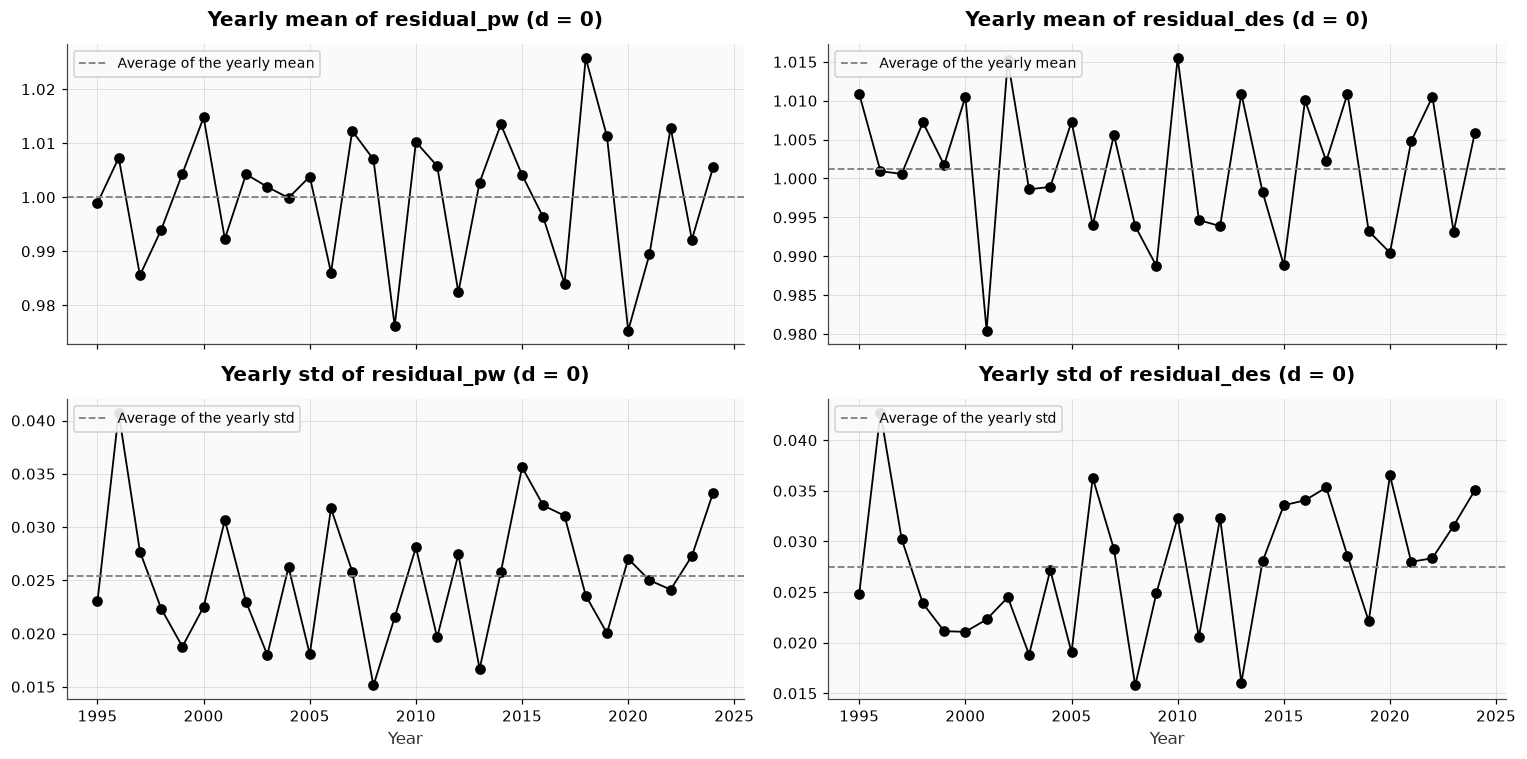

In [18]:
import warnings

from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore", category=FutureWarning)  # adfuller return-type notice


def stationarity_tests(series):
    """ADF test + t-tests on the slope of the yearly mean and yearly std."""
    adf_stat, adf_p, used_lag, *_ = adfuller(series, regression="c", autolag="AIC")
    # One window per calendar year, like in section 1.1
    yearly = series.groupby(series.index.year).agg(mean="mean", std="std")
    # Fit mean_i = alpha + beta * i and std_i = alpha + beta * i, then t-test on H0: beta = 0
    X_year = sm.add_constant(np.arange(len(yearly)))
    p_mean = sm.OLS(yearly["mean"], X_year).fit().pvalues.iloc[1]
    p_std = sm.OLS(yearly["std"], X_year).fit().pvalues.iloc[1]
    stationary = adf_p < alpha and p_mean >= alpha and p_std >= alpha
    return {"adf": adf_stat, "adf_p": adf_p, "used_lag": used_lag, "p_mean": p_mean, "p_std": p_std,
            "yearly": yearly, "stationary": stationary}


residual_cols = ["residual_pw", "residual_des"]
max_d = 2
# levels[col][k] is the series differenced k times; the last one is the stationary series
levels = {}
tests = {}
for col in residual_cols:
    levels[col] = [df_train[col]]
    for d in range(max_d + 1):
        result = stationarity_tests(levels[col][-1])
        print(
            f"{col}, d = {d}: ADF = {result['adf']:.3f} (p-value = {result['adf_p']:.4f}, {result['used_lag']} lags) | "
            f"slope of yearly mean: p-value = {result['p_mean']:.3f} | slope of yearly std: p-value = {result['p_std']:.3f}"
        )
        if result["stationary"] or d == max_d:
            break
        # Not stationary: difference once more, dR_t = R_t - R_{t-1}
        levels[col].append(levels[col][-1].diff().dropna())
    tests[col] = result
    verdict = "stationary" if result["stationary"] else "NOT stationary"
    print(f"-> {col} is {verdict} with d = {len(levels[col]) - 1}\n")

fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
for j, col in enumerate(residual_cols):
    yearly = tests[col]["yearly"]
    for i, stat in enumerate(["mean", "std"]):
        ax = axes[i, j]
        ax.plot(yearly.index, yearly[stat], marker="o", color="black")
        ax.axhline(yearly[stat].mean(), color="grey", linestyle="--", label=f"Average of the yearly {stat}")
        ax.set_title(f"Yearly {stat} of {col} (d = {len(levels[col]) - 1})")
        ax.legend(loc="upper left")
for ax in axes[1]:
    ax.set_xlabel("Year")
plt.tight_layout()
plt.show()

> Is $R_t$ stationary?

Both residuals are **stationary without differencing** ($d = 0$):

| Series | ADF (p-value) | Slope of the yearly mean (p-value) | Slope of the yearly std (p-value) |
|---|---|---|---|
| `residual_pw` | -11.73 (< 0.0001) | 0.995 | 0.589 |
| `residual_des` | -6.78 (< 0.0001) | 0.676 | 0.160 |

The ADF test rejects the unit root at 5%, and neither the yearly mean nor the yearly std has a significant trend. On the plots, the yearly mean and std move around their average without any drift. This is the result we wanted from the piecewise linear trend: with the straight line, the ADF test failed (section 1.4.1).

### 1.5.2. PACF - Partial AutoCorrelation Function
The partial autocorrelation $\phi_{kk}$ at lag $k$ is the correlation between $R_t$ and $R_{t-k}$ once the effect of the intermediate lags $R_{t-1}, \dots, R_{t-k+1}$ has been removed. We compute it by OLS: $\phi_{kk}$ is the last coefficient of the AR($k$) regression

$$R_t = c + \phi_{k1} \, R_{t-1} + \phi_{k2} \, R_{t-2} + \dots + \phi_{kk} \, R_{t-k} + \varepsilon_t$$

**Significance:** under $H_0$: $\phi_{kk} = 0$, $\hat{\phi}_{kk}$ is approximately $\mathcal{N}(0, 1/n)$. Lag $k$ is significant at 5% if

$$|\hat{\phi}_{kk}| > \frac{1.96}{\sqrt{n}}$$

With $n = 360$ months, the band is about $\pm 0.103$. We look at the first 24 lags (two seasonal cycles).


residual_pw: band = +/-0.103, significant lags = [1, 10, 13, 15, 21, 24]
  phi_kk of the first lags: [ 0.443 -0.02  -0.019 -0.032]
residual_des: band = +/-0.103, significant lags = [1, 7, 10, 15, 21, 24]
  phi_kk of the first lags: [ 0.363 -0.065 -0.062 -0.072]


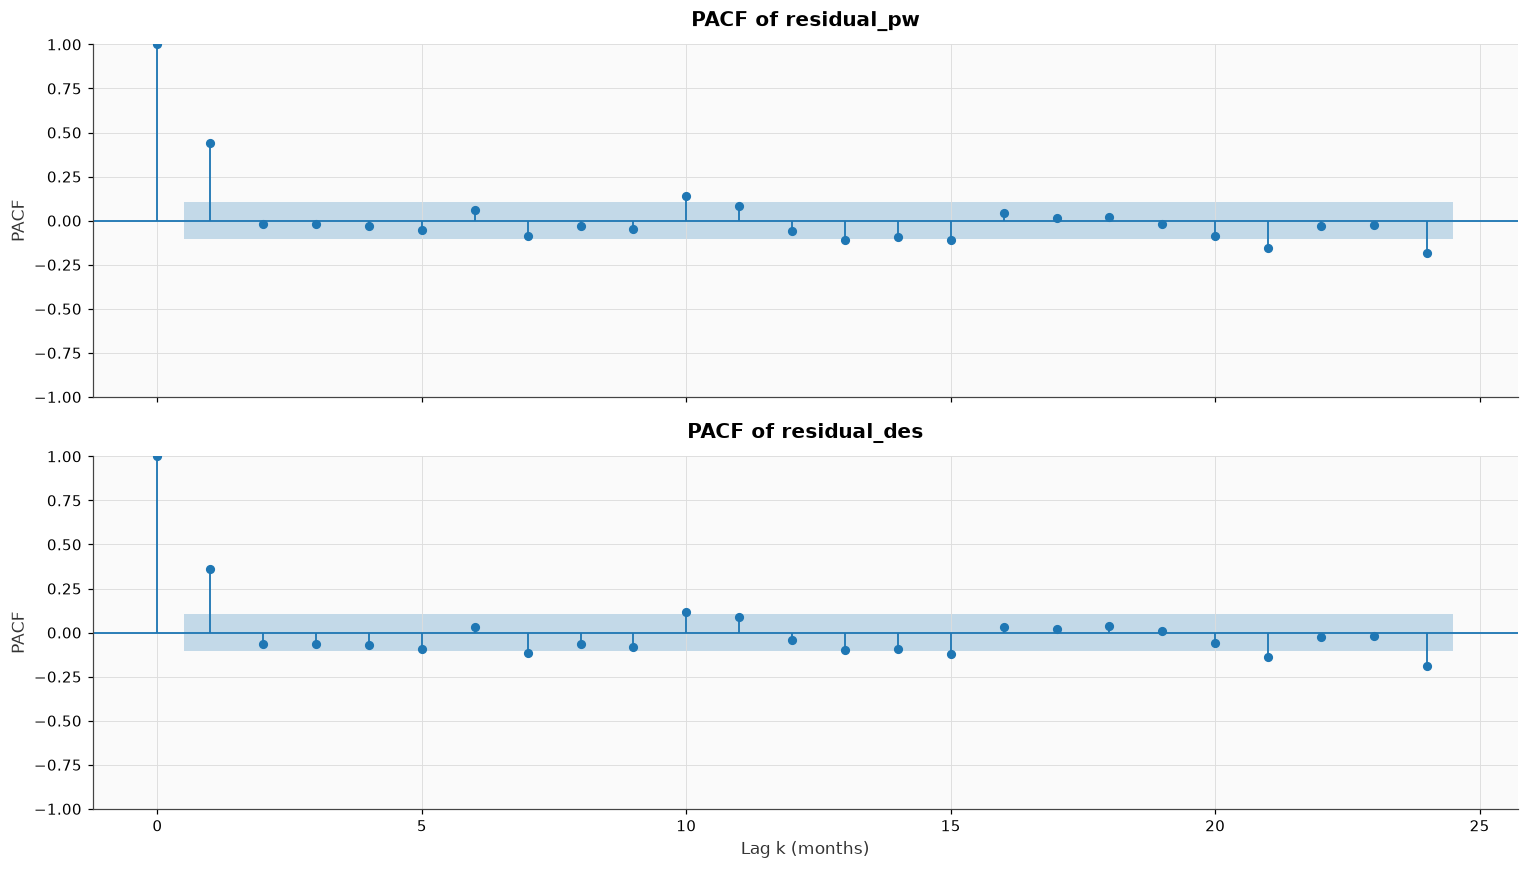

In [19]:
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.stattools import pacf

n_lags = 24  # two full seasonal cycles

significant_lags = {}
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, col in zip(axes, residual_cols):
    z = levels[col][-1]  # stationary series
    # PACF computed by OLS: phi_kk is the last coefficient of the AR(k) regression
    phi_kk = pacf(z, nlags=n_lags, method="ols")
    bound = 1.96 / np.sqrt(len(z))  # 95% confidence band under H0: phi_kk = 0
    significant_lags[col] = [k for k in range(1, n_lags + 1) if abs(phi_kk[k]) > bound]
    print(f"{col}: band = +/-{bound:.3f}, significant lags = {significant_lags[col]}")
    print(f"  phi_kk of the first lags: {np.round(phi_kk[1:5], 3)}")

    plot_pacf(z, lags=n_lags, method="ols", ax=ax, title=f"PACF of {col}")
    ax.set_ylabel("PACF")
axes[1].set_xlabel("Lag k (months)")
plt.tight_layout()
plt.show()

> Significant lags

| Series | Significant lags $k$ |
|---|---|
| `residual_pw` | 1, 10, 13, 15, 21, 24 |
| `residual_des` | 1, 7, 10, 15, 21, 24 |

For both residuals, lag 1 is by far the strongest ($\hat{\phi}_{11} = 0.44$ for the piecewise linear trend and $0.36$ for DES): a month above its trend is often followed by another one, for example when a cold spell lasts over two months. The first autocorrelation is weaker for DES because this trend already absorbs a part of the persistence.

The other significant lags are far (7 to 24 months) and close to the band. They are hard to explain physically, and some may be due to chance: with 24 lags tested at 5%, about one false positive is expected. The Ljung-Box test of the next section will tell whether they are needed.

### 1.5.3. ARIMA
When $d = 0$, the ARIMA($p$, $d$, 0) model reduces to an AR model on $R_t$, fitted only on a set of lags $K = \{k_1, \dots, k_p\}$:

$$R_t = c + \sum_{k \in K} \phi_k \, R_{t-k} + \varepsilon_t$$

**Estimation:** OLS regression of $R_t$ on its lagged values $R_{t-k}$, $k \in K$

**Ljung-Box test** on the regression residuals $\hat{\varepsilon}_t$, with $\hat{\rho}_j$ the autocorrelation of $\hat{\varepsilon}_t$ at lag $j$:

$$Q(h) = n(n+2) \sum_{j=1}^{h} \frac{\hat{\rho}_j^2}{n - j} \sim \chi^2(h - p) \text{ under } H_0$$

- $H_0$: no autocorrelation up to lag $h$, the residuals are white noise
- $H_1$: at least one $\rho_j \neq 0$

We use $h = 12$ and $h = 24$, and remove the $p$ estimated coefficients from the degrees of freedom. We reject $H_0$ at 5% if the p-value is below 0.05. The residuals are white noise if $H_0$ is not rejected at both $h$.

**Lag selection (Box-Jenkins iteration):**
1. Start with $K$ = the significant lags of the PACF (section 1.5.2), fit the model and run the Ljung-Box test.
2. If $H_0$ is rejected, some structure is left in $\hat{\varepsilon}_t$. The candidates are the lags $j \notin K$ where the residual ACF is significant: $|\hat{\rho}_j| > 1.96 / \sqrt{n}$.
3. Refit the model once with each candidate added to $K$, and keep the candidate that gives the smallest $Q(24)$, i.e. the one that removes the most autocorrelation.
4. Repeat from step 1 until $H_0$ is not rejected, until no candidate is left, or after 10 steps.

**Recursive forecast** over the test period ($n$ = last train month, $h = 1, \dots, 20$):

$$\hat{R}_{n+h} = \hat{c} + \sum_{k \in K} \hat{\phi}_k \, \tilde{R}_{n+h-k} \qquad \text{with } \tilde{R}_s = \begin{cases} R_s & \text{if } s \le n \text{ (observed)} \\ \hat{R}_s & \text{if } s > n \text{ (already forecast)} \end{cases}$$

The future errors $\varepsilon_{n+h}$ are replaced by their expected value, 0. This is the best guess only if $\varepsilon_t$ is white noise, which is why the Ljung-Box test should pass before forecasting.

If the series had been differenced, we would forecast $\Delta R_t$ and integrate back with $\hat{R}_{n+h} = \hat{R}_{n+h-1} + \widehat{\Delta R}_{n+h}$. The code does it automatically when $d > 0$.


===== residual_pw, step 1: lags [1, 10, 13, 15, 21, 24] =====
R2 = 0.254
      lb_stat  lb_pvalue
12  15.539602   0.016450
24  20.131760   0.325451
H0 rejected: the residuals are NOT white noise
Significant residual ACF at lags [9], Q(24) after adding each: {9: np.float64(9.4)}
-> add lag 9 and refit

===== residual_pw, step 2: lags [1, 9, 10, 13, 15, 21, 24] =====
R2 = 0.271
     lb_stat  lb_pvalue
12  6.710856   0.243048
24  9.411657   0.926456
H0 not rejected: the residuals are white noise

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.1512      0.127      9.092      0.000       0.902       1.400
lag_1          0.3804      0.048      7.860      0.000       0.285       0.476
lag_9         -0.1482      0.052     -2.829      0.005      -0.251      -0.045
lag_10         0.1354      0.052      2.584      0.010       0.032       0.238
lag_13        -0.0604      

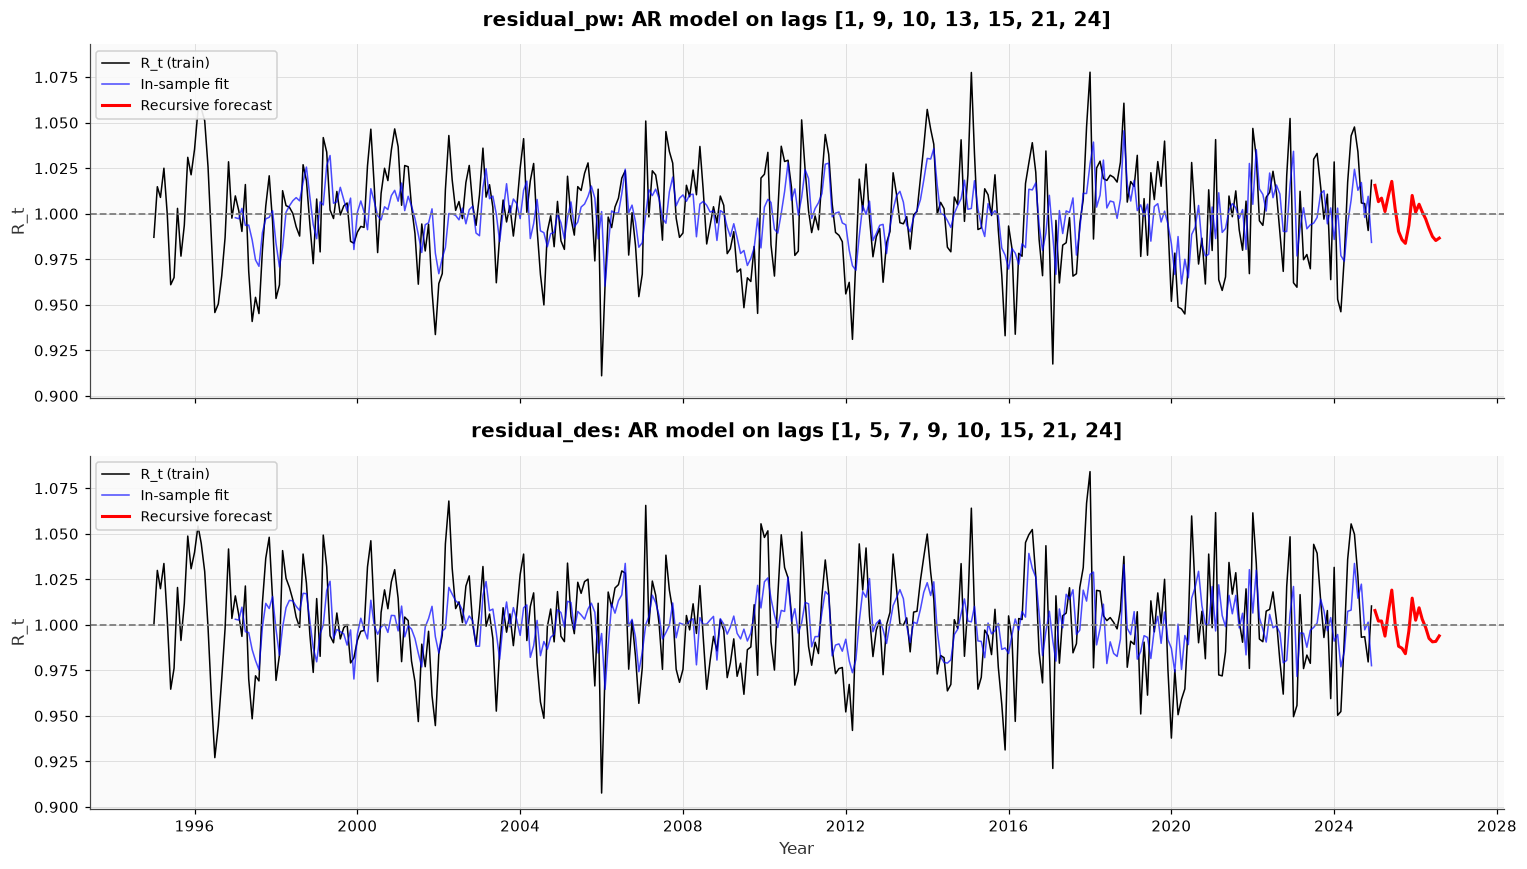

,residual_pw,residual_des
date,,
2025-01-01,1.015566,1.007856
2025-02-01,1.006607,1.002058
2025-03-01,1.008563,1.002107
2025-04-01,1.001186,0.993811
2025-05-01,1.009844,1.006857
2025-06-01,1.017760,1.019076
2025-07-01,1.002765,1.000535
2025-08-01,0.990300,0.988250
2025-09-01,0.985694,0.987112


In [20]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf


def fit_ar(z, lags):
    """OLS regression z_t = c + sum_k phi_k * z_{t-k} + e_t, on the given lags only."""
    X_lags = pd.concat({f"lag_{k}": z.shift(k) for k in lags}, axis=1)
    data = pd.concat([z.rename("z"), X_lags], axis=1).dropna()
    return sm.OLS(data["z"], sm.add_constant(data[X_lags.columns])).fit()


def ljung_box(resid, n_params):
    """Ljung-Box test at h = 12 and 24. Q follows a chi2(h - p) under H0, p = number of AR coefficients."""
    return acorr_ljungbox(resid, lags=[12, 24], model_df=n_params)


max_steps = 10  # safety net for the Box-Jenkins iteration
ar_models = {}
ar_lags = {}
residual_forecast = pd.DataFrame(index=df_test.index)
for col in residual_cols:
    z = levels[col][-1]
    # Step 1: start from the significant PACF lags
    lags = list(significant_lags[col])
    step = 1
    while True:
        ar = fit_ar(z, lags)
        lb = ljung_box(ar.resid, len(lags))
        white_noise = (lb["lb_pvalue"] >= alpha).all()
        print(f"===== {col}, step {step}: lags {lags} =====")
        print(f"R2 = {ar.rsquared:.3f}")
        print(lb)
        if white_noise:
            print("H0 not rejected: the residuals are white noise\n")
            break
        print("H0 rejected: the residuals are NOT white noise")
        if step == max_steps:
            print("Maximum number of steps reached: we stop and keep this model\n")
            break

        # Step 2: the candidates are the lags where the residual ACF is significant
        rho = acf(ar.resid, nlags=n_lags)
        bound = 1.96 / np.sqrt(len(ar.resid))
        candidates = [k for k in range(1, n_lags + 1) if abs(rho[k]) > bound and k not in lags]
        if not candidates:
            print("No significant lag left in the residual ACF: we stop and keep this model\n")
            break
        # Refit with each candidate and keep the one that removes the most autocorrelation (smallest Q(24))
        q24 = {k: ljung_box(fit_ar(z, sorted(lags + [k])).resid, len(lags) + 1)["lb_stat"].iloc[-1] for k in candidates}
        new_lag = min(q24, key=q24.get)
        print(f"Significant residual ACF at lags {candidates}, Q(24) after adding each: "
              f"{ {k: round(q, 1) for k, q in q24.items()} }")
        print(f"-> add lag {new_lag} and refit\n")
        lags = sorted(lags + [new_lag])
        step += 1
    ar_models[col] = ar
    ar_lags[col] = lags
    print(ar.summary().tables[1])

    # Recursive forecast: each prediction is fed back as a lagged value for the next months
    history = list(z.to_numpy())
    for _ in range(len(df_test)):
        history.append(ar.params["const"] + sum(ar.params[f"lag_{k}"] * history[-k] for k in lags))
    forecast = pd.Series(history[-len(df_test):], index=df_test.index)

    # If the series was differenced, integrate back: R_{n+h} = R_{n+h-1} + dR_{n+h}
    for level in reversed(levels[col][:-1]):
        forecast = level.iloc[-1] + forecast.cumsum()
    residual_forecast[col] = forecast

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, sharey=True)
for ax, col in zip(axes, residual_cols):
    fitted = ar_models[col].fittedvalues
    ax.plot(df_train.index, df_train[col], color="black", linewidth=1, label="R_t (train)")
    if len(levels[col]) == 1:
        ax.plot(fitted.index, fitted, color="blue", linewidth=1, alpha=0.7, label="In-sample fit")
    ax.plot(residual_forecast.index, residual_forecast[col], color="red", linewidth=2, label="Recursive forecast")
    ax.axhline(1, color="grey", linestyle="--")
    ax.set_title(f"{col}: AR model on lags {ar_lags[col]}")
    ax.set_ylabel("R_t")
    ax.legend(loc="upper left")
axes[1].set_xlabel("Year")
plt.tight_layout()
plt.show()

residual_forecast

> ARIMA results

| Series | Step | Lags $K$ | $R^2$ | Ljung-Box $h = 12$ (p-value) | Ljung-Box $h = 24$ (p-value) | White noise? |
|---|---|---|---|---|---|---|
| `residual_pw` | 1 (PACF) | 1, 10, 13, 15, 21, 24 | 0.254 | 0.016 | 0.325 | No |
| `residual_pw` | 2 (+ lag 9) | 1, 9, 10, 13, 15, 21, 24 | 0.271 | 0.243 | 0.926 | **Yes** |
| `residual_des` | 1 (PACF) | 1, 7, 10, 15, 21, 24 | 0.187 | 0.003 | 0.080 | No |
| `residual_des` | 2 (+ lag 9) | 1, 7, 9, 10, 15, 21, 24 | 0.209 | 0.042 | 0.493 | No (at $h = 12$) |
| `residual_des` | 3 (+ lag 5) | 1, 5, 7, 9, 10, 15, 21, 24 | 0.215 | 0.072 | 0.526 | **Yes** |

With only the PACF lags, the Ljung-Box test rejects white noise at $h = 12$ for both models. The Box-Jenkins iteration adds lag 9 (and lag 5 for DES), after which **the residuals of both AR models are white noise** at $h = 12$ and $h = 24$. Some coefficients are not significant on their own (for example lag 13 for the piecewise linear trend), but removing them would bring back the autocorrelation, so we keep them.

The $R^2$ is low (0.27 and 0.22): the AR model only explains about a quarter of $R_t$. This is expected, since most of the residual is weather, which cannot be predicted from the past months. As a consequence, the forecast of $R_t$ goes back to its mean (about 1) after a few months, and the residual brings little information for the second half of the test period.

## 1.6. Forecast and Recomposition
We now have a forecast for each component, so we can recompose the series with the multiplicative model $Y_t = T_t \cdot S_t \cdot R_t$. We do it twice, once with the piecewise linear trend and once with the double exponential smoothing (DES) trend.

**Trend forecast** ($n$ = last train month, $h = 1, \dots, 20$):
- Piecewise linear: $\hat{T}_{n+h} = \hat{b} + \hat{a} \, (n + h) + \hat{c}_1 \, (n + h - \tau_1) + \hat{c}_2 \, (n + h - \tau_2)$, i.e. the last segment extended
- DES: $\hat{T}_{n+h} = b_n + h \cdot a_n$ (already computed in section 1.4.2)

**Seasonal forecast:** $\hat{S}_{n+h} = S_m$, the seasonal coefficient of the calendar month (section 1.3.2).

**Residual forecast:** $\hat{R}_{n+h}$, the recursive AR forecast of section 1.5.3 (one per trend).

**Recomposition:**
- On the train set (in-sample fit): $\hat{Y}_t = T_t \cdot S_t \cdot \hat{R}_t$, with $\hat{R}_t$ the fitted values of the AR model. The first $\max(K)$ months have no fitted value because their lags are missing.
- On the test set (forecast of January 2025 to August 2026): $\hat{Y}_{n+h} = \hat{T}_{n+h} \cdot \hat{S}_{n+h} \cdot \hat{R}_{n+h}$


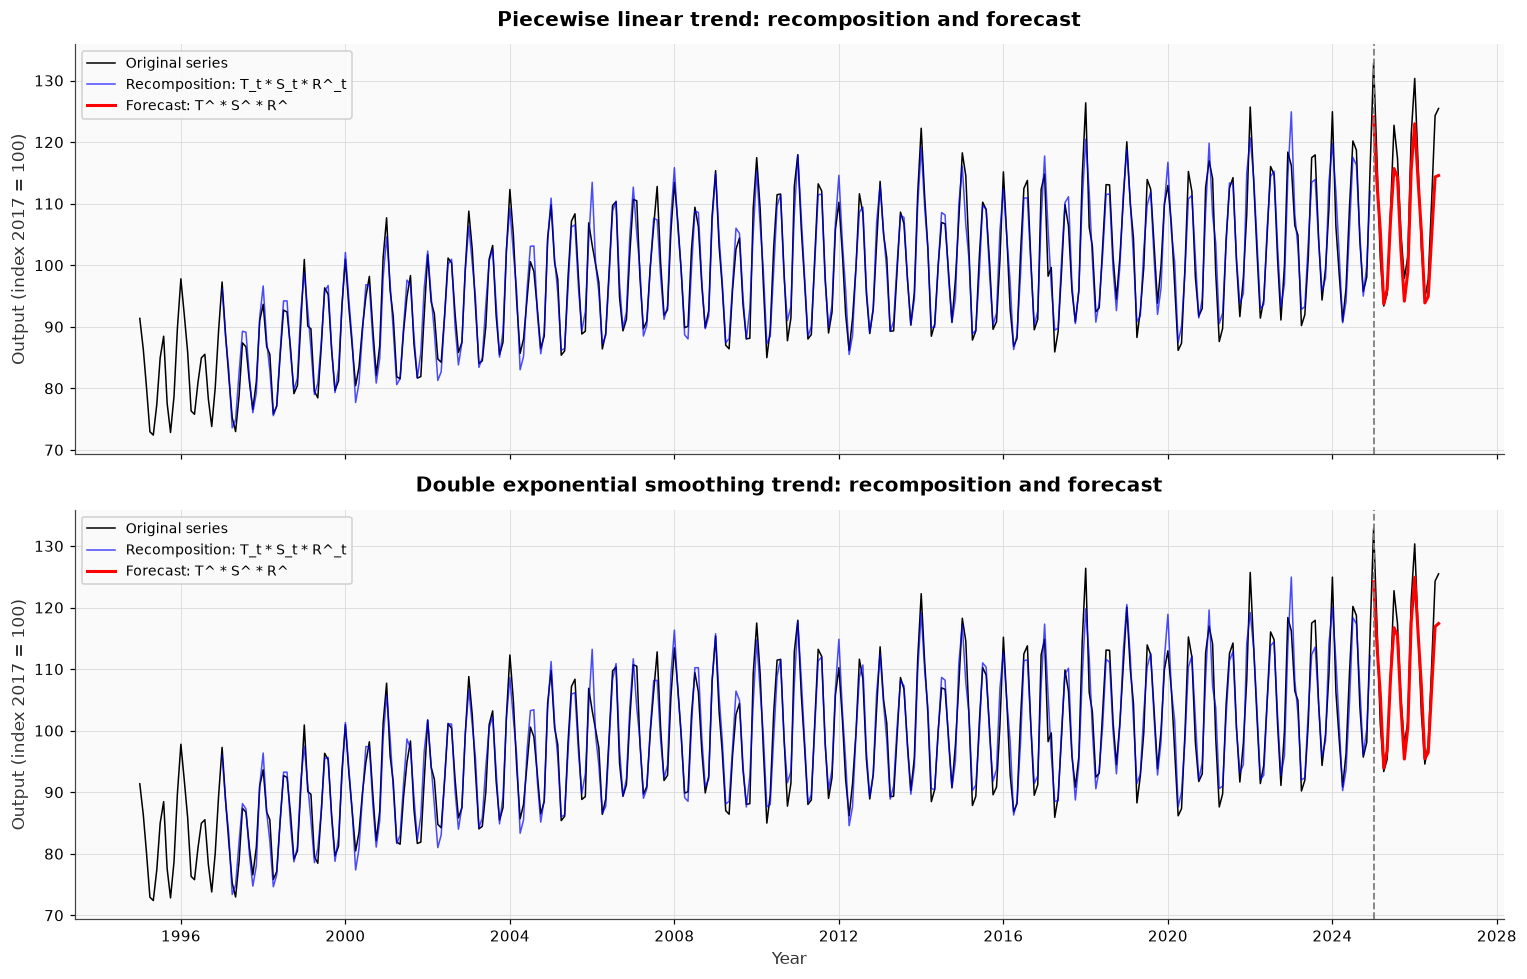

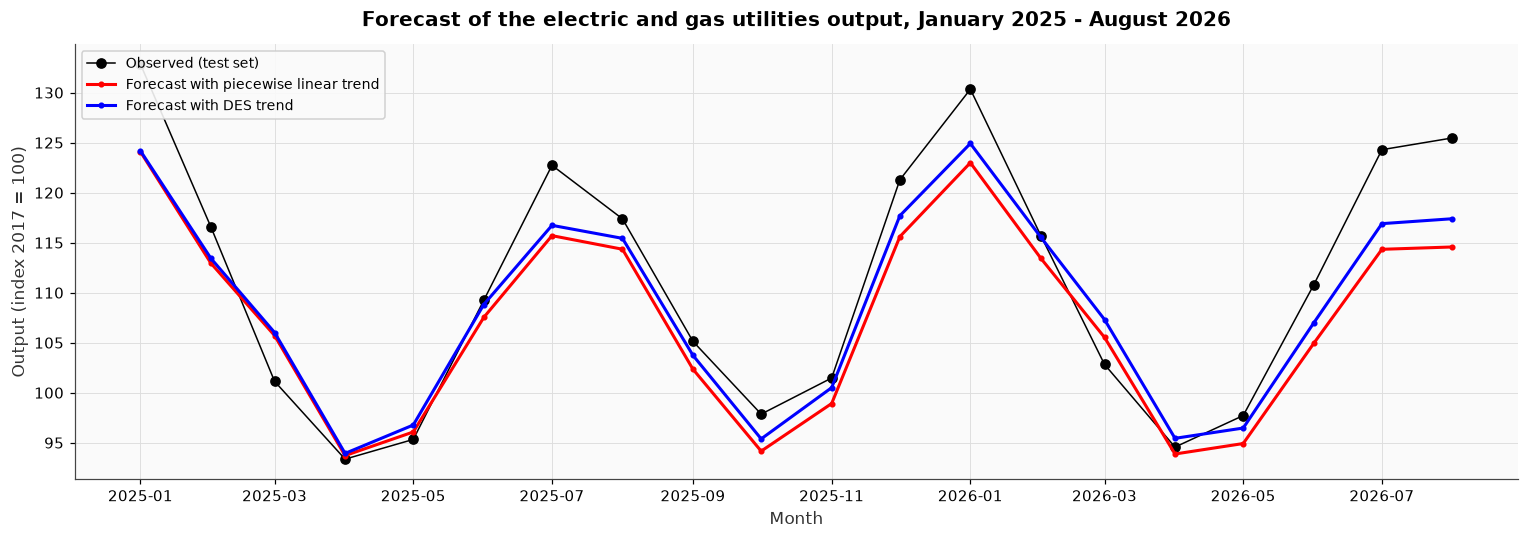

,output,trend_pw,trend_des,seasonal,residual_pw,residual_des,forecast_pw,forecast_des
date,,,,,,,,
2025-01-01,132.8431,106.224193,107.114740,1.150264,1.015566,1.007856,124.087889,124.178204
2025-02-01,116.5641,106.275111,107.215244,1.055780,1.006607,1.002058,112.944486,113.428626
2025-03-01,101.1350,106.326030,107.315748,0.985816,1.008563,1.002107,105.715411,106.016441
2025-04-01,93.3597,106.376948,107.416252,0.879923,1.001186,0.993811,93.714550,93.933087
2025-05-01,95.3301,106.427867,107.516756,0.893925,1.009844,1.006857,96.075114,96.771012


In [21]:
# Piecewise linear trend forecast: extend the last segment over the test horizon (t = n+1, ..., n+h)
t_test = np.arange(len(df_train) + 1, len(df_train) + len(df_test) + 1)
trend_pw_forecast = pd.Series(pw_trend.predict(hinge_design(t_test, breaks)), index=df_test.index)

# Seasonal forecast: each future month gets the coefficient of its calendar month
seasonal_forecast = pd.Series(df_test.index.month.map(seasonal_coef).to_numpy(), index=df_test.index)

# In-sample recomposition on the train set: Y^_t = T_t * S_t * R^_t, with R^_t the AR fitted values
# (NaN for the first max(K) months, whose lags are missing)
df_train = df_train.assign(
    recomposed_pw=df_train["trend_pw"] * df_train["seasonal"] * ar_models["residual_pw"].fittedvalues,
    recomposed_des=df_train["trend_des"] * df_train["seasonal"] * ar_models["residual_des"].fittedvalues,
)

# Forecast over the test period: Y^_{n+h} = T^_{n+h} * S^_{n+h} * R^_{n+h}
df_forecast = pd.DataFrame(
    {
        "output": df_test["output"],
        "trend_pw": trend_pw_forecast,
        "trend_des": trend_des_forecast,
        "seasonal": seasonal_forecast,
        "residual_pw": residual_forecast["residual_pw"],
        "residual_des": residual_forecast["residual_des"],
    }
)
df_forecast = df_forecast.assign(
    forecast_pw=df_forecast["trend_pw"] * df_forecast["seasonal"] * df_forecast["residual_pw"],
    forecast_des=df_forecast["trend_des"] * df_forecast["seasonal"] * df_forecast["residual_des"],
)

# Full period: recomposition on the train set and forecast on the test set
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True, sharey=True)
methods = [
    (axes[0], "recomposed_pw", "forecast_pw", "Piecewise linear trend"),
    (axes[1], "recomposed_des", "forecast_des", "Double exponential smoothing trend"),
]
for ax, recomposed_col, forecast_col, name in methods:
    ax.plot(df.index, df["output"], color="black", linewidth=1, label="Original series")
    ax.plot(df_train.index, df_train[recomposed_col], color="blue", linewidth=1, alpha=0.7, label="Recomposition: T_t * S_t * R^_t")
    ax.plot(df_forecast.index, df_forecast[forecast_col], color="red", linewidth=2, label="Forecast: T^ * S^ * R^")
    ax.axvline(df_test.index[0], color="grey", linestyle="--")
    ax.set_title(f"{name}: recomposition and forecast")
    ax.set_ylabel("Output (index 2017 = 100)")
    ax.legend(loc="upper left")
axes[1].set_xlabel("Year")
plt.tight_layout()
plt.show()

# Zoom on the test period: both forecasts against the observed values
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_forecast.index, df_forecast["output"], color="black", marker="o", linewidth=1, label="Observed (test set)")
ax.plot(df_forecast.index, df_forecast["forecast_pw"], color="red", marker=".", linewidth=2, label="Forecast with piecewise linear trend")
ax.plot(df_forecast.index, df_forecast["forecast_des"], color="blue", marker=".", linewidth=2, label="Forecast with DES trend")
ax.set_title("Forecast of the electric and gas utilities output, January 2025 - August 2026")
ax.set_xlabel("Month")
ax.set_ylabel("Output (index 2017 = 100)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

df_forecast.head(5)

> Forecast and recomposition

On the train set, both recompositions follow the original series closely: the trend gives the level, the seasonal coefficients give the two peaks per year, and the AR model on $R_t$ corrects a small part of the deviations.

On the test set, both forecasts have the right seasonal shape, with the winter and summer peaks at the right months, and they are very close to each other (the DES forecast is slightly higher). The low months (April-May, October) are well forecast. The **peaks are underestimated**: January 2025 (132.8 observed, about 124 forecast), July 2025, January 2026, and above all July-August 2026 (about 125 observed, 114-117 forecast).

We will measure these errors precisely in the next section.

## 1.7. Errors measurement
We compare the forecast $\hat{Y}_t$ with the observed values $Y_t$ of the test set, for both trends. With $e_t = Y_t - \hat{Y}_t$ and $N$ the number of forecast months:

| Metric | Formula | Meaning |
|---|---|---|
| ME (Mean Error) | $\frac{1}{N} \sum_t e_t$ | Bias: $> 0$ if the forecast is too low on average, $< 0$ if too high |
| MAE (Mean Absolute Error) | $\frac{1}{N} \sum_t \lvert e_t \rvert$ | Average size of the error, in index points |
| MSE (Mean Squared Error) | $\frac{1}{N} \sum_t e_t^2$ | Squared error: large errors weigh a lot |
| RMSE (Root Mean Squared Error) | $\sqrt{\frac{1}{N} \sum_t e_t^2}$ | Like the MSE, but in the unit of the series |
| MAPE (Mean Absolute Percentage Error) | $\frac{100}{N} \sum_t \frac{\lvert e_t \rvert}{Y_t}$ | Average error in % of the observed value |
| sMAPE (symmetric MAPE) | $\frac{100}{N} \sum_t \frac{2 \lvert e_t \rvert}{\lvert Y_t \rvert + \lvert \hat{Y}_t \rvert}$ | Like the MAPE, but over- and under-forecasts are penalized the same way |

We compute them on the full test set (20 months), then on the complete year 2025 (12 months) and on January-August 2026 (8 months) separately.


ME  MAE   MSE  RMSE  MAPE (%)  \
Period             Method                                                   
2025-01 -> 2026-08 Piecewise linear trend  3.5  4.4  28.0   5.3       3.7   
                   DES trend               2.1  3.3  18.0   4.2       2.9   
2025               Piecewise linear trend  2.8  3.7  19.4   4.4       3.2   
                   DES trend               1.8  3.0  14.4   3.8       2.6   
2026-01 -> 2026-08 Piecewise linear trend  4.6  5.3  40.9   6.4       4.5   
                   DES trend               2.6  3.9  23.3   4.8       3.3   

                                           sMAPE (%)  
Period             Method                             
2025-01 -> 2026-08 Piecewise linear trend        3.8  
                   DES trend                     2.9  
2025               Piecewise linear trend        3.3  
                   DES trend                     2.6  
2026-01 -> 2026-08 Piecewise linear trend        4.6  
                   DES trend                     3.4

date,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01,2026-07-01,2026-08-01
Piecewise linear trend,-6.6,-3.1,4.5,0.4,0.8,-1.6,-5.7,-2.6,-2.6,-3.8,-2.5,-4.7,-5.6,-2.0,2.6,-0.7,-2.9,-5.3,-8.0,-8.7
DES trend,-6.5,-2.7,4.8,0.6,1.5,-0.4,-4.9,-1.7,-1.3,-2.5,-1.0,-3.0,-4.2,-0.1,4.4,0.9,-1.3,-3.4,-5.9,-6.4


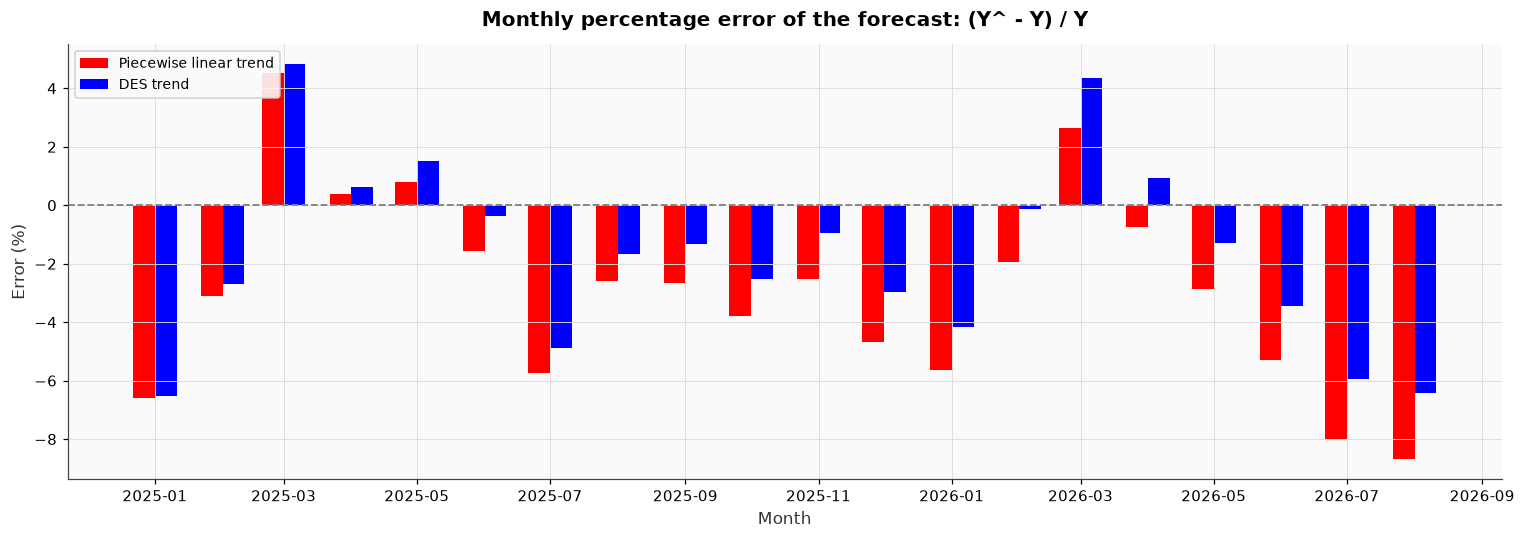

In [22]:
def error_metrics(y, y_hat):
    """ME, MAE, MSE, RMSE, MAPE and sMAPE between the observed values y and the forecast y_hat."""
    e = y - y_hat
    return {
        "ME": e.mean(),
        "MAE": e.abs().mean(),
        "MSE": (e**2).mean(),
        "RMSE": np.sqrt((e**2).mean()),
        "MAPE (%)": 100 * (e.abs() / y).mean(),
        "sMAPE (%)": 100 * (2 * e.abs() / (y.abs() + y_hat.abs())).mean(),
    }


forecast_cols = {"Piecewise linear trend": "forecast_pw", "DES trend": "forecast_des"}
# Full test set, then the complete year 2025 and the first eight months of 2026 separately
periods = {
    "2025-01 -> 2026-08": df_forecast,
    "2025": df_forecast.loc["2025"],
    "2026-01 -> 2026-08": df_forecast.loc["2026"],
}
errors = pd.DataFrame(
    {
        (period, method): error_metrics(data["output"], data[col])
        for period, data in periods.items()
        for method, col in forecast_cols.items()
    }
).T
errors.index.names = ["Period", "Method"]
display(errors.round(1))

# Monthly percentage error (y_hat - y) / y, to see where the forecasts miss
monthly_errors = pd.DataFrame(
    {method: 100 * (df_forecast[col] - df_forecast["output"]) / df_forecast["output"] for method, col in forecast_cols.items()}
)
display(monthly_errors.round(1).T)

fig, ax = plt.subplots(figsize=(14, 5))
width = 10  # bar width, in days
for shift, (method, col), color in zip([-5, 5], forecast_cols.items(), ["red", "blue"]):
    pct_error = 100 * (df_forecast[col] - df_forecast["output"]) / df_forecast["output"]
    ax.bar(df_forecast.index + pd.Timedelta(days=shift), pct_error, width=width, color=color, label=method)
ax.axhline(0, color="grey", linestyle="--")
ax.set_title("Monthly percentage error of the forecast: (Y^ - Y) / Y")
ax.set_xlabel("Month")
ax.set_ylabel("Error (%)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

> Errors measurement

Over the full test set, the **DES trend is better than the piecewise linear trend** on every metric, with a MAPE of 2.9% against 3.7% (RMSE of 4.2 against 5.3 points). Both are good forecasts: an average error below 4% of the observed value.

The ME is positive for both methods (3.5 for the piecewise linear trend, 2.1 for DES): the forecasts are **too low on average**. The monthly errors show where: the piecewise linear forecast is below the observed value in 16 months out of 20, the DES forecast in 15. The largest errors are on the peaks (January 2025: about -6.5%, July-August 2026: -6% to -9%), while the spring months are close or even slightly over-forecast (March 2025 and March 2026: between +2.6% and +4.8%).

The errors grow with the horizon (2026 is worse than 2025 for both methods). Two reasons can explain the bias:
- **The level rose faster than the trend.** The 2025 average is about 109.5, against 106.6 in 2024 (+2.7%), while the last segment of the piecewise linear trend only adds 0.6 point per year. DES, whose last slope is 1.2 points per year, follows this better, which is why it wins.
- **The weather.** A colder winter or a hotter summer than usual raises the peaks, and no model based on the calendar can know it in advance. The fact that the largest errors are all on peak months points in this direction.